<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-scientific-discovery/blob/main/notebooks/lecture-07/physics-informed-networks.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

# Physics-informed neural networks

*Deep Learning for Scientific Discovery, Jagiellonian University. Author Marcin Płodzień.*

Differential equations whose form is known but whose coefficients are partly unknown appear in every natural science, for example the diffusion of heat or of a dissolved substance in tissue, soil or groundwater, rate equations in chemical kinetics and growth models in population dynamics. Measurements in such systems are often sparse and noisy, and a method that combines the law with a few measurements to estimate the solution and the unknown coefficients is useful across these fields.

A physics-informed neural network (PINN) represents the solution of a differential equation by a neural network and trains the network to satisfy the equation. The network $x_\theta(t)$ is the solution itself. It receives the time $t$ as input and returns the position of the system at that time. Its time derivatives follow from automatic differentiation, the application of the chain rule to the operations of the network, and they are the derivatives of the network function itself, with no discretisation of time. The loss adds a data part, which measures the distance of $x_\theta$ from the initial conditions and, when available, from a few measurements, and the residual of the known law, which measures how far $x_\theta$ is from satisfying the equation of motion at a set of sample times called collocation points. A neural ODE learns an unknown law from trajectories, while a PINN assumes the law and learns its solution. The idea goes back to Lagaris, Likas and Fotiadis [IEEE Trans. Neural Netw. **9**, 987 (1998), [doi:10.1109/72.712178](https://doi.org/10.1109/72.712178)], and Raissi, Perdikaris and Karniadakis gave it its present form and name [J. Comput. Phys. **378**, 686 (2019), [doi:10.1016/j.jcp.2018.10.045](https://doi.org/10.1016/j.jcp.2018.10.045)].

The construction is attractive when a physical law is known but its solution is wanted together with information that a classical solver cannot use directly. The network is a function of continuous coordinates, so the equation is enforced at arbitrary sample points without a mesh. Measurements enter the same loss as the equation, so a few sparse or noisy data points and the law together determine the solution, and an unknown coefficient of the law can be trained together with the network. Such inverse problems are the main application of PINNs. For a plain forward problem with known coefficients and known initial and boundary conditions a classical solver is faster and more accurate, and our experiments measure the size of this difference.

We work with three classical systems. The damped harmonic oscillator, a mass on a spring slowed down by friction, has an analytical solution, a formula for $x(t)$, so every error of the network can be measured against it. The heat equation in a rod is a partial differential equation in space and time with a solution by separation of variables, a sum of products of a function of position and a function of time. The nonlinear pendulum has no solution in elementary functions, and we compare the network with a fourth-order Runge–Kutta (RK4) integration, a standard numerical method that advances the state from four evaluations of the right-hand side per step. We first describe the physics of the oscillator and the pendulum, their phase portraits, the curves traced by the state in the plane of position and velocity, and their energies. We then build the PINN, draw it, train it on the oscillator and compare its accuracy and its cost with two classical solvers, our own RK4 and the adaptive solver of the library diffrax. Two further experiments show what the physics term of the loss adds to a fit of sparse data and how the same construction estimates an unknown damping coefficient from noisy observations. The heat equation repeats the comparison for a partial differential equation, first against a finite-difference solver and then in the inverse problem of measuring the thermal diffusivity of the rod with a few thermometers. The pendulum over several periods exhibits failures of PINN training. The comparisons of cost with classical solvers, the check of our own Adam optimiser against the library and the training of the pendulum one period at a time, called time marching, go deeper than the lecture, which uses only their main results.

The implementation uses JAX in double precision. The network, its derivatives and the loss are written with `jax.grad`, `jax.hessian` and `jax.vmap`, the optimisers come from `optax` and are checked against our own Adam, and the classical integrations use our RK4 next to `diffrax`.

> **Google Colab execution**
> 1. Go to <https://colab.research.google.com> → *File → Upload notebook*. Execution starts with `JAX_PLATFORMS=cpu`. The complete notebook includes repeated training runs; its final cell reports the measured runtime on your CPU.
> 2. `jax`, `optax`, `scipy` and `matplotlib` are pre-installed in Colab. diffrax is installed with `pip install diffrax`.
> 3. Run the cells *in order*. Later cells use variables defined earlier.

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"     # run JAX on the CPU (set before importing jax)

import json, time
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyBboxPatch
from scipy.special import ellipk
from scipy.optimize import least_squares

import jax, jax.numpy as jnp
jax.config.update("jax_enable_x64", True)   # all computations of this notebook in float64
from jax.experimental import io_callback
import optax
import diffrax

# common style of the notebook figures
mpl.rcParams.update({"font.size": 14, "axes.labelsize": 15, "axes.titlesize": 15,
                     "xtick.labelsize": 13, "ytick.labelsize": 13, "legend.fontsize": 12,
                     "figure.titlesize": 16, "lines.linewidth": 2.0,
                     "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False})
# slide figures are drawn at their printed size (5.5 in = full width of a slide), so these are true font sizes
SLIDE_RC = {"font.size": 11, "axes.labelsize": 11, "axes.titlesize": 11, "xtick.labelsize": 11,
            "ytick.labelsize": 11, "legend.fontsize": 11, "lines.linewidth": 1.4, "figure.dpi": 150}

UJBlue, UJNavy, DSOrange, UJGray = "#005CA7", "#002B5C", "#D35A05", "#5A6270"
COL = {"exact": "k", "PINN": "#7B4FA0", "RK4": DSOrange, "Tsit5": "#2A9D8F", "data": UJBlue}

OUT = "figures"
os.makedirs(OUT, exist_ok=True)
def save(fig, name):
    # slide figures are created at their printed size and saved as PDF (slides) and PNG
    for ext in ("pdf", "png"):
        fig.savefig(f"{OUT}/{name}.{ext}", dpi=300, bbox_inches="tight", pad_inches=0.02)

nums = {}                 # every number a slide may need, written to the numbers file at the end
t_start = time.time()
print("jax", jax.__version__, "| optax", optax.__version__, "| diffrax", diffrax.__version__)

jax 0.11.0 | optax 0.2.6 | diffrax 0.7.2


<hr/>
## 1. Damped harmonic oscillator

A mass $m$ on a spring of stiffness $k$ that moves through a viscous medium, such as oil or air, with friction coefficient $c$ obeys Newton's equation
$$m\ddot x+c\dot x+kx=0,\qquad x(0)=x_0,\quad \dot x(0)=v_0 . \tag{1}$$
The friction term $c\dot x$ is the damping. It opposes the velocity and turns the energy of the motion into heat, so the oscillation decays. With the decay rate $\gamma=c/2m$, the natural angular frequency $\omega_0=\sqrt{k/m}$ and the damping ratio $\zeta=\gamma/\omega_0$, the motion is oscillatory for $\zeta<1$ (underdamped). The trial solution $e^{\lambda t}$ gives $\lambda=-\gamma\pm i\omega_d$ with $\omega_d=\omega_0\sqrt{1-\zeta^2}$, and the solution with the given initial conditions is
$$x(t)=e^{-\gamma t}\Big[x_0\cos\omega_dt+\frac{v_0+\gamma x_0}{\omega_d}\sin\omega_dt\Big]. \tag{2}$$
The mechanical energy $E=\tfrac12m\dot x^2+\tfrac12kx^2$ is not conserved. Multiplying the equation of motion by $\dot x$ gives
$$\frac{dE}{dt}=-c\,\dot x^2\le0 , \tag{3}$$
so friction removes energy at every instant except the turning points, where $\dot x=0$. Averaged over one period the energy decays as $e^{-2\gamma t}$, twice the rate of the amplitude.

We take $m=1$, $c=0.4$, $k=4$, $x_0=1$, $v_0=0$ and the time window $0\le t\le10$. We evaluate $\zeta$, $\omega_d$ and the period $2\pi/\omega_d$, check the analytical velocity $\dot x(t)$ against a finite difference of $x(t)$, and compare the energy at the end of the window with $e^{-2\gamma t}$.

In [2]:
M, C_TRUE, K = 1.0, 0.4, 4.0          # mass, damping coefficient, spring constant
X0, V0, T_END = 1.0, 0.0, 10.0        # initial position and velocity, end of the time window
GAMMA = C_TRUE / (2 * M)              # decay rate of the amplitude
OMEGA0 = np.sqrt(K / M)               # natural angular frequency
ZETA = GAMMA / OMEGA0                 # damping ratio, < 1 for the underdamped oscillator
OMEGA_D = OMEGA0 * np.sqrt(1 - ZETA**2)

def x_exact(t, c=C_TRUE, x0=X0, v0=V0):
    # underdamped solution with x(0) = x0, xdot(0) = v0
    g = c / (2 * M); wd = np.sqrt(K / M - g**2)
    return np.exp(-g * t) * (x0 * np.cos(wd * t) + (v0 + g * x0) / wd * np.sin(wd * t))

def v_exact(t, c=C_TRUE, x0=X0, v0=V0):
    g = c / (2 * M); wd = np.sqrt(K / M - g**2)
    return np.exp(-g * t) * (v0 * np.cos(wd * t) - (g * v0 + (g**2 + wd**2) * x0) / wd * np.sin(wd * t))

def energy(x, v):
    return 0.5 * M * v**2 + 0.5 * K * x**2

# check the closed-form velocity against a central finite difference of x(t)
tt = np.linspace(0, T_END, 2001)
fd = (x_exact(tt + 1e-6) - x_exact(tt - 1e-6)) / 2e-6
print(f"zeta = {ZETA:.3f}, omega_0 = {OMEGA0:.3f}, omega_d = {OMEGA_D:.4f}, period 2 pi/omega_d = {2*np.pi/OMEGA_D:.3f},"
      f" periods in the window = {T_END * OMEGA_D / (2*np.pi):.2f}")
print(f"max |v_exact - finite difference of x_exact| = {np.abs(v_exact(tt) - fd).max():.1e}")
print(f"E(T)/E(0) = {energy(x_exact(T_END), v_exact(T_END)) / energy(X0, V0):.4f}, exp(-2 gamma T) = {np.exp(-2*GAMMA*T_END):.4f}")
nums["osc"] = dict(zeta=ZETA, omega0=OMEGA0, omegad=OMEGA_D, period=2*np.pi/OMEGA_D, n_periods=T_END*OMEGA_D/(2*np.pi),
                   E_ratio=float(energy(x_exact(T_END), v_exact(T_END)) / energy(X0, V0)))

zeta = 0.100, omega_0 = 2.000, omega_d = 1.9900, period 2 pi/omega_d = 3.157, periods in the window = 3.17
max |v_exact - finite difference of x_exact| = 5.5e-10
E(T)/E(0) = 0.0202, exp(-2 gamma T) = 0.0183


The damping ratio is $\zeta=0.100$ and $\omega_d=1.9900$, so the window of 10 time units contains 3.17 periods of length $2\pi/\omega_d=3.157$. The analytical velocity agrees with the finite difference to $5.5\times10^{-10}$, and at $t=10$ the energy is 0.0202 of its initial value, close to $e^{-2\gamma t}=0.0183$. The left panel shows $x(t)$ inside its envelope $\pm e^{-\gamma t}$. The middle panel is the phase portrait, the trajectory in the plane of position $x$ and velocity $\dot x$, which spirals from the initial state (dot) towards the equilibrium at the origin. The right panel shows the energy $E(t)$ divided by its initial value $E_0=\tfrac12kx_0^2$ on a logarithmic axis, together with $e^{-2\gamma t}$. The energy decreases in steps, fastest where the speed is largest, and follows the exponential on average.

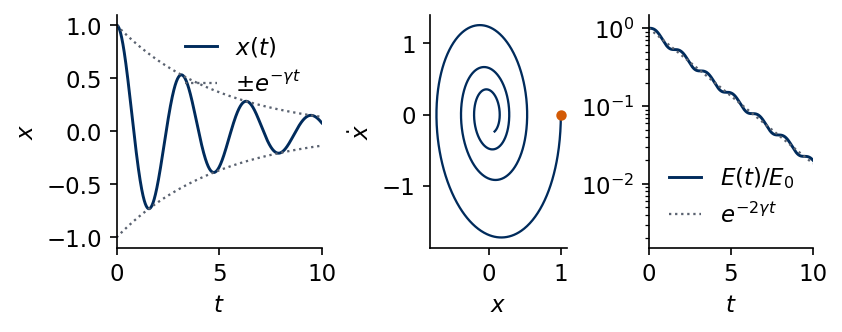

In [3]:
xe, ve = x_exact(tt), v_exact(tt)
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 3, figsize=(5.5, 2.1), layout="constrained", gridspec_kw={"width_ratios": [1.5, 1, 1.2]})
    axs[0].plot(tt, xe, color=UJNavy, label="$x(t)$")
    axs[0].plot(tt, np.exp(-GAMMA * tt), ":", color=UJGray, lw=1.1, label=r"$\pm e^{-\gamma t}$")
    axs[0].plot(tt, -np.exp(-GAMMA * tt), ":", color=UJGray, lw=1.1)
    axs[0].set_xlabel("$t$"); axs[0].set_ylabel("$x$"); axs[0].set_xlim(0, T_END)
    axs[0].legend(loc="upper right", handlelength=1.4, fontsize=11)
    axs[1].plot(xe, ve, color=UJNavy, lw=1.1); axs[1].plot([X0], [V0], "o", color=DSOrange, ms=4)
    axs[1].set_xlabel("$x$"); axs[1].set_ylabel(r"$\dot x$")
    axs[2].semilogy(tt, energy(xe, ve) / energy(X0, V0), color=UJNavy, label="$E(t)/E_0$")
    axs[2].semilogy(tt, np.exp(-2 * GAMMA * tt), ":", color=UJGray, lw=1.1, label=r"$e^{-2\gamma t}$")
    axs[2].set_xlabel("$t$"); axs[2].set_xlim(0, T_END); axs[2].set_ylim(1.5e-3, 1.5)
    axs[2].legend(loc="lower left", fontsize=11, handlelength=1.4)
    save(fig, "fig_lab041_oscillator"); plt.show()

### Nonlinear pendulum

A point mass on a massless rod of length $\ell$ in the gravitational field $g$ moves according to
$$\ddot\theta=-\omega_p^2\sin\theta,\qquad \omega_p^2=g/\ell , \tag{4}$$
where $\theta$ is the angle from the downward vertical. For small angles $\sin\theta\approx\theta$ and the pendulum is a harmonic oscillator of angular frequency $\omega_p$. For finite angles the restoring force grows more slowly than $\theta$ and the period becomes longer. Without friction the energy per unit $m\ell^2$,
$$E=\tfrac12\dot\theta^2-\omega_p^2\cos\theta , \tag{5}$$
is conserved, so every trajectory lies on a contour line of $E$ in the phase plane $(\theta,\dot\theta)$. The contour $E=\omega_p^2$ is the separatrix. It passes through the unstable upright position $\theta=\pm\pi$ and separates the oscillations ($E<\omega_p^2$) from the rotations over the top ($E>\omega_p^2$).

The equation has no solution in elementary functions. For a pendulum released at rest from $\theta_0$ the energy conservation gives the period $T_p$ as an integral, which becomes [S. H. Strogatz, *Nonlinear Dynamics and Chaos*, 2nd ed., CRC Press (2018), [doi:10.1201/9780429492563](https://doi.org/10.1201/9780429492563)]
$$T_p=\frac{4}{\omega_p}K(q),\qquad q=\sin\frac{\theta_0}{2},\qquad K(q)=\int_0^{\pi/2}\frac{d\eta}{\sqrt{1-q^2\sin^2\eta}} , \tag{6}$$
with $K$ the complete elliptic integral of the first kind and $q$ its modulus. We measure time in units of $1/\omega_p$, set $\omega_p=1$, and release the pendulum from $\theta_0=2$ rad (about 115 degrees) at rest. The reference solution comes from our RK4 integrator with step $h=10^{-3}$. One RK4 step for $\dot{\mathbf y}=\mathbf f(\mathbf y)$ evaluates the right-hand side four times,
$$\mathbf k_1=\mathbf f(\mathbf y_n),\ \ \mathbf k_2=\mathbf f\big(\mathbf y_n+\tfrac h2\mathbf k_1\big),\ \ \mathbf k_3=\mathbf f\big(\mathbf y_n+\tfrac h2\mathbf k_2\big),\ \ \mathbf k_4=\mathbf f(\mathbf y_n+h\mathbf k_3), \tag{7}$$
$$\mathbf y_{n+1}=\mathbf y_n+\tfrac h6(\mathbf k_1+2\mathbf k_2+2\mathbf k_3+\mathbf k_4), \tag{8}$$
and its global error decreases as $h^4$ [E. Hairer, S. P. Nørsett, G. Wanner, *Solving Ordinary Differential Equations I*, 2nd ed., Springer (1993), [doi:10.1007/978-3-540-78862-1](https://doi.org/10.1007/978-3-540-78862-1)]. We check the period from the elliptic integral against the times between successive maxima of the RK4 solution, and we monitor the conservation of $E$.

In [4]:
OMEGA_P2, TH0 = 1.0, 2.0              # g/l (time unit 1/omega_p) and initial angle in rad, started at rest
Q_ELL = np.sin(TH0 / 2)               # elliptic modulus q = sin(theta_0/2)
T_PEND = 4 * ellipk(Q_ELL**2) / np.sqrt(OMEGA_P2)     # period, scipy's ellipk takes the parameter q^2

def rk4_step(f, y, h):
    # one classical fourth-order Runge-Kutta step for dy/dt = f(y)
    k1 = f(y); k2 = f(y + 0.5 * h * k1); k3 = f(y + 0.5 * h * k2); k4 = f(y + h * k3)
    return y + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4)

def rk4_solve(f, y0, h, n):
    # n RK4 steps of size h, returns the states at t = 0, h, ..., n h
    _, ys = jax.lax.scan(lambda y, _: (rk4_step(f, y, h),) * 2, jnp.asarray(y0), None, length=n)
    return jnp.concatenate([jnp.asarray(y0)[None], ys])

f_pend = lambda y: jnp.array([y[1], -OMEGA_P2 * jnp.sin(y[0])])
H_REF = 1e-3
n_ref = int(round(8 * T_PEND / H_REF))
t_pend = np.arange(n_ref + 1) * H_REF
Y_pend = np.asarray(rk4_solve(f_pend, [TH0, 0.0], H_REF, n_ref))       # reference solution over eight periods
E_pend = 0.5 * Y_pend[:, 1]**2 - OMEGA_P2 * np.cos(Y_pend[:, 0])
# period from the RK4 solution: times at which thetadot changes sign from + to - (maxima of theta), linear interpolation
w = Y_pend[:, 1]
i = np.nonzero((w[:-1] > 0) & (w[1:] <= 0))[0]
t_max = t_pend[i] + H_REF * w[i] / (w[i] - w[i + 1])
print(f"period from the elliptic integral {T_PEND:.6f}, from the RK4 maxima {np.diff(t_max).mean():.6f},"
      f" small-angle period 2 pi = {2*np.pi:.4f}")
print(f"relative energy drift of RK4 (h = {H_REF}) over eight periods: {np.abs(E_pend - E_pend[0]).max() / abs(E_pend[0]):.1e}")
nums["pend"] = dict(theta0=TH0, period=T_PEND, period_rk4=float(np.diff(t_max).mean()), ratio_small=T_PEND / (2*np.pi))

period from the elliptic integral 8.349753, from the RK4 maxima 8.349753, small-angle period 2 pi = 6.2832
relative energy drift of RK4 (h = 0.001) over eight periods: 4.9e-14


The period from the elliptic integral, $T_p=8.349753$, agrees with the spacing of the RK4 maxima in all printed digits and is 1.329 times the small-angle period $2\pi=6.2832$. Over eight periods the RK4 energy deviates from its initial value by at most $4.9\times10^{-14}$ in relative terms, so the integration is an accurate reference. The left panel shows the contour lines of $E$ in the phase plane (grey), the separatrix (dashed) and the orbit of our pendulum over one period (orange), which starts at the dot. The orbit is closer to the separatrix than to the small ellipses around the origin, and its shape is visibly flattened. The right panel compares $\theta(t)$ over two periods with the small-angle solution $\theta_0\cos\omega_pt$. The nonlinear pendulum lags behind more with every period.

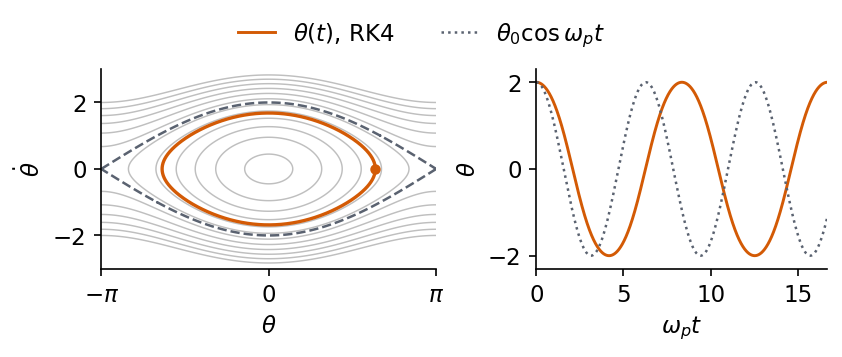

In [5]:
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.3), layout="constrained", gridspec_kw={"width_ratios": [1.15, 1]})
    th, om = np.meshgrid(np.linspace(-np.pi, np.pi, 301), np.linspace(-3, 3, 241))
    Egrid = 0.5 * om**2 - OMEGA_P2 * np.cos(th)
    axs[0].contour(th, om, Egrid, levels=np.linspace(-0.9, 3.0, 12), colors="0.75", linewidths=0.7,
                   linestyles="solid")
    axs[0].contour(th, om, Egrid, levels=[OMEGA_P2], colors=[UJGray], linewidths=1.2, linestyles="--")
    m1 = t_pend <= T_PEND
    axs[0].plot(Y_pend[m1, 0], Y_pend[m1, 1], color=DSOrange, lw=1.6)
    axs[0].plot([TH0], [0], "o", color=DSOrange, ms=4)
    axs[0].set_xlabel(r"$\theta$"); axs[0].set_ylabel(r"$\dot\theta$")
    axs[0].set_xticks([-np.pi, 0, np.pi]); axs[0].set_xticklabels([r"$-\pi$", "0", r"$\pi$"])
    m2 = t_pend <= 2 * T_PEND
    axs[1].plot(t_pend[m2], Y_pend[m2, 0], color=DSOrange, label=r"$\theta(t)$, RK4")
    axs[1].plot(t_pend[m2], TH0 * np.cos(np.sqrt(OMEGA_P2) * t_pend[m2]), ":", color=UJGray, lw=1.2,
                label=r"$\theta_0\cos\omega_p t$")
    axs[1].set_xlabel(r"$\omega_p t$"); axs[1].set_ylabel(r"$\theta$"); axs[1].set_xlim(0, 2 * T_PEND)
    axs[1].set_ylim(-2.3, 2.3)
    fig.legend(*axs[1].get_legend_handles_labels(), loc="outside upper center", ncol=2, fontsize=11, handlelength=1.6)
    save(fig, "fig_lab041_pendulum"); plt.show()

<hr/>
## 2. Physics-informed neural network

A neural ODE learns a map from a state to a velocity and uses a numerical solver to construct trajectories. Here the equation is given and the unknown is one solution curve. The PINN maps a time directly to a position. Every choice of network weights proposes a whole curve, and training checks that curve against the equation and the information that selects the required motion. This basic PINN represents one initial-value problem on a chosen interval; changing the initial conditions generally requires another fit.

| Experiment | Given information | Quantities trained |
|---|---|---|
| Forward oscillator | $m,c,k,x_0,v_0$ | Network weights |
| Sparse-data reconstruction | $m,c,k$ and 12 positions | Network weights |
| Inverse damping | $m,k$ and 25 noisy positions | Network weights and $\log c$ |
| Inverse heat diffusion | Initial/boundary conditions and thermometer readings | Network weights and $\log D$ |

The inverse experiments also reconstruct the trajectory or field. That reconstruction from a model and incomplete observations is data assimilation.

The PINN replaces the unknown function $x(t)$ by a multilayer perceptron $x_\theta(t)$ with parameters $\theta$. The input $t\in[0,T]$ is first rescaled to $\tau=2t/T-1\in[-1,1]$, then passes through three hidden layers of 32 tanh units each, and a linear output unit returns the number $x_\theta(t)$,
$$\mathbf h_1=\tanh(W_1\tau+\mathbf b_1),\qquad \mathbf h_{l+1}=\tanh(W_{l+1}\mathbf h_l+\mathbf b_{l+1}),\qquad x_\theta(t)=W_4\mathbf h_3+b_4 . \tag{9}$$
Because the network is a composition of smooth functions, its derivatives $\dot x_\theta=\partial_tx_\theta$ and $\ddot x_\theta=\partial_t^2x_\theta$ exist at every $t$. Automatic differentiation evaluates them by applying the chain rule to the same composition, so they equal the derivatives of the network function up to round-off and involve no finite differences. With them we form the residual of the equation of motion,
$$r_\theta(t)=\frac{m\ddot x_\theta(t)+c\dot x_\theta(t)+kx_\theta(t)}{k}, \tag{10}$$
which vanishes for every $t$ when $x_\theta$ solves the equation. Dividing by $k$ gives the residual the units of a position.

The drawing shows the network as nodes and edges on the left. The boxes on the right show how the derivatives in $t$, the residual and the initial conditions are assembled into the loss of equation (11).

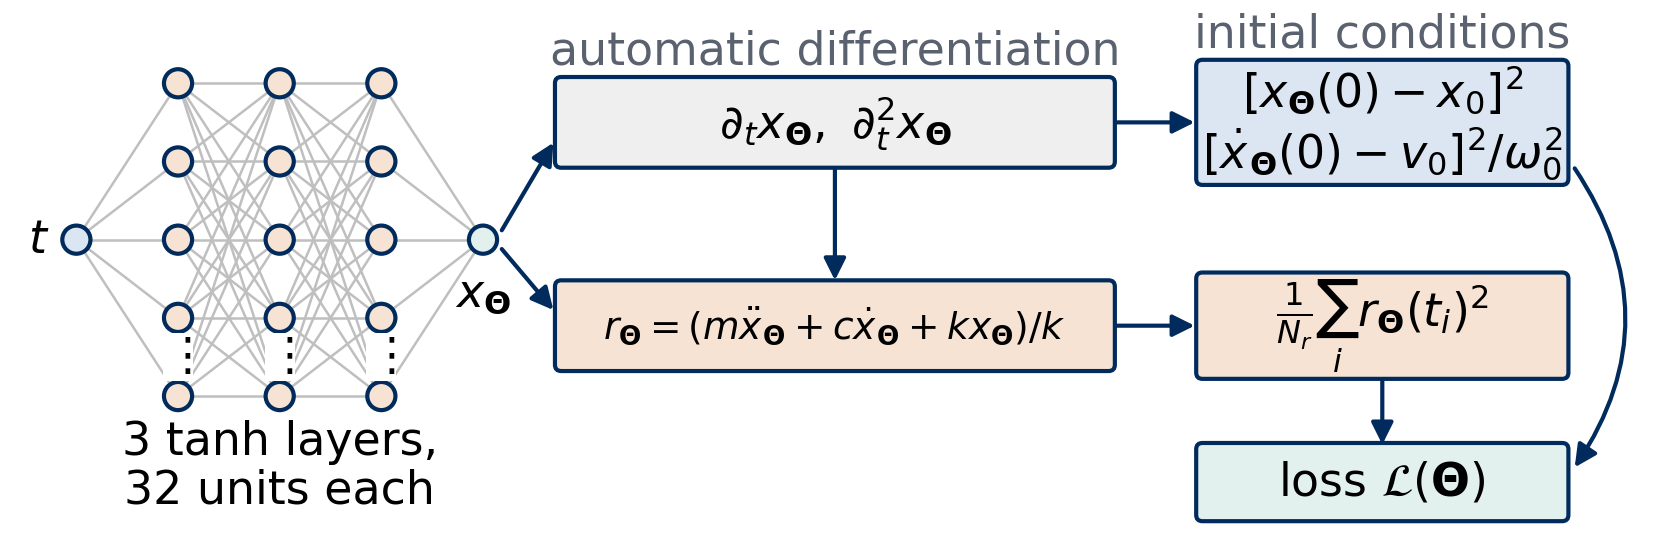

In [6]:
def draw_layers(ax, sizes, labels, xs, ys_span=2.2, node_r=0.11, colors=None, edge_color="0.75"):
    """Nodes-and-edges drawing of a fully connected network, columns at x = xs, labels below the columns."""
    cols = []
    for n, x in zip(sizes, xs):
        ys = np.linspace(ys_span / 2, -ys_span / 2, n) if n > 1 else np.array([0.0])
        cols.append([(x, y) for y in ys])
    for a, b in zip(cols[:-1], cols[1:]):            # edges first, so that the nodes are drawn on top
        for (x0, y0) in a:
            for (x1, y1) in b:
                ax.plot([x0, x1], [y0, y1], color=edge_color, lw=0.6, zorder=1)
    for i, col in enumerate(cols):
        for (x, y) in col:
            ax.add_patch(Circle((x, y), node_r, fc=(colors[i] if colors else "#DCE6F2"), ec=UJNavy, lw=1.0, zorder=3))
    for i, lab in enumerate(labels):
        ax.text(xs[i], -ys_span / 2 - 0.25, lab, ha="center", va="top", linespacing=1.1)
    return cols

def box(ax, x, y, text, w, h, fc, **kw):
    ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0.04", fc=fc, ec=UJNavy, lw=1.0, zorder=3))
    ax.text(x, y, text, ha="center", va="center", zorder=4, **kw)

def arrow(ax, p, q, **kw):
    ax.annotate("", xy=q, xytext=p, arrowprops=dict(arrowstyle="-|>", color=UJNavy, lw=1.0, shrinkA=0, shrinkB=0, **kw), zorder=2)

WIDTH, DEPTH = 32, 3
with mpl.rc_context(SLIDE_RC):
    fig = plt.figure(figsize=(5.5, 1.85)); ax = fig.add_axes([0, 0, 1, 1])
    cols = draw_layers(ax, [1, 5, 5, 5, 1], ["", "", "", "", ""], xs=[0, 0.65, 1.3, 1.95, 2.6], ys_span=2.0, node_r=0.09,
                       colors=["#DCE6F2", "#F6E3D3", "#F6E3D3", "#F6E3D3", "#E3F1EE"])
    for col in cols[1:4]:
        ax.text(col[0][0], 0.5 * (col[-2][1] + col[-1][1]), r"$\vdots$", ha="center", va="center", zorder=4,
                bbox=dict(fc="white", ec="none", pad=0.3))
    ax.text(-0.17, 0, "$t$", ha="right", va="center")
    ax.text(2.6, -0.2, r"$x_{\boldsymbol{\Theta}}$", ha="center", va="top")
    ax.text(1.3, -1.15, f"{DEPTH} tanh layers,\n{WIDTH} units each", ha="center", va="top", linespacing=1.1, fontsize=11)
    # automatic differentiation in t and the residual
    xm, wm = 4.85, 3.5
    box(ax, xm, 0.75, r"$\partial_t x_{\boldsymbol{\Theta}},\ \partial_t^2 x_{\boldsymbol{\Theta}}$", wm, 0.5, "#EFEFEF", fontsize=11)
    ax.text(xm, 1.06, "automatic differentiation", ha="center", va="bottom", fontsize=11, color=UJGray)
    box(ax, xm, -0.55, r"$r_{\boldsymbol{\Theta}}=(m\ddot x_{\boldsymbol{\Theta}}+c\dot x_{\boldsymbol{\Theta}}+kx_{\boldsymbol{\Theta}})/k$", wm, 0.5, "#F6E3D3", fontsize=9)
    arrow(ax, (2.72, 0.06), (xm - wm / 2 - 0.05, 0.62)); arrow(ax, (2.72, -0.06), (xm - wm / 2 - 0.05, -0.45))
    arrow(ax, (xm, 0.46), (xm, -0.26))
    # loss terms
    xr, wr = 8.35, 2.3
    box(ax, xr, 0.75, r"$[x_{\boldsymbol{\Theta}}(0)-x_0]^2$" + "\n" + r"$[\dot x_{\boldsymbol{\Theta}}(0)-v_0]^2/\omega_0^2$", wr, 0.72, "#DCE6F2", fontsize=11)
    ax.text(xr, 1.17, "initial conditions", ha="center", va="bottom", fontsize=11, color=UJGray)
    box(ax, xr, -0.55, r"$\frac{1}{N_r}\sum_i r_{\boldsymbol{\Theta}}(t_i)^2$", wr, 0.6, "#F6E3D3", fontsize=11)
    box(ax, xr, -1.55, r"loss $\mathcal{L}(\boldsymbol{\Theta})$", wr, 0.42, "#E3F1EE", fontsize=11)
    arrow(ax, (xm + wm / 2 + 0.05, 0.75), (xr - wr / 2 - 0.05, 0.75)); arrow(ax, (xm + wm / 2 + 0.05, -0.55), (xr - wr / 2 - 0.05, -0.55))
    arrow(ax, (xr, -0.9), (xr, -1.31))
    ax.annotate("", xy=(xr + wr / 2 + 0.05, -1.5), xytext=(xr + wr / 2 + 0.05, 0.5), zorder=2,
                arrowprops=dict(arrowstyle="-|>", color=UJNavy, lw=1.0, connectionstyle="arc3,rad=-0.35"))
    ax.set_xlim(-0.45, 10.1); ax.set_ylim(-1.85, 1.5); ax.set_aspect("equal"); ax.axis("off")
    save(fig, "fig_lab041_pinn_architecture"); plt.show()

The network has $1\cdot32+32+2\,(32\cdot32+32)+32+1$ parameters. The call `jax.grad(net, argnums=1)` differentiates the network with respect to its time argument, and applying `jax.grad` again gives the second derivative. We compare both with central finite differences at four times on the untrained network.

There are two different derivatives in training. Differentiation with respect to the input time gives the velocity and acceleration of the candidate curve. Differentiation of the resulting scalar loss with respect to the network parameters gives the update direction. The first derivatives are not estimates from noisy measurements. The time rescaling is inside `net`, so automatic differentiation includes its chain-rule factors $2/T$ and $(2/T)^2$.

For a simple check use $x_A(t)=A\cos(2t)$ with the oscillator parameters above. Substitution gives
$$r_A(t)=\frac{-4A\cos(2t)-0.8A\sin(2t)+4A\cos(2t)}4=-0.2A\sin(2t).$$
At $A=1$ the initial conditions hold but the undamped candidate violates the damped equation. At $A=0$ the residual is zero everywhere but the initial position is wrong. The following cell evaluates these two candidates at $t=\pi/4$ without any measured target position there.


In [7]:
def init_mlp(key, sizes):
    # LeCun normal weights (variance 1/n_in) and zero biases, one (W, b) pair per layer
    params = []
    for n_in, n_out in zip(sizes[:-1], sizes[1:]):
        key, sub = jax.random.split(key)
        params.append((jax.random.normal(sub, (n_out, n_in)) / np.sqrt(n_in), jnp.zeros(n_out)))
    return params

def make_net(t_a, t_b):
    # scalar network x_theta(t) on the window [t_a, t_b]; the input is rescaled to [-1, 1]
    def net(params, t):
        h = jnp.atleast_1d(2 * (t - t_a) / (t_b - t_a) - 1)
        for W, b in params[:-1]:
            h = jnp.tanh(W @ h + b)
        W, b = params[-1]
        return (W @ h + b)[0]
    d1 = jax.grad(net, argnums=1)          # dx_theta/dt
    d2 = jax.grad(d1, argnums=1)           # d^2x_theta/dt^2
    return net, d1, d2

def n_params(params):
    return int(sum(W.size + b.size for W, b in params))

SIZES = [1] + [WIDTH] * DEPTH + [1]
net, d1, d2 = make_net(0.0, T_END)
p_test = init_mlp(jax.random.key(0), SIZES)
# automatic derivatives against central finite differences at a few times
ts = jnp.array([0.3, 2.7, 6.1, 9.4]); e = 1e-4
fd1 = jax.vmap(lambda t: (net(p_test, t + e) - net(p_test, t - e)) / (2 * e))(ts)
fd2 = jax.vmap(lambda t: (net(p_test, t + e) - 2 * net(p_test, t) + net(p_test, t - e)) / e**2)(ts)
print(f"network {SIZES}, {n_params(p_test)} parameters")
print(f"max |d1 - finite difference| = {jnp.abs(jax.vmap(lambda t: d1(p_test, t))(ts) - fd1).max():.1e},"
      f" max |d2 - finite difference| = {jnp.abs(jax.vmap(lambda t: d2(p_test, t))(ts) - fd2).max():.1e}")
nums["n_params"] = n_params(p_test)

# Two candidate curves: one passes the law test, the other the initial-condition test.
for amplitude in (0.0, 1.0):
    candidate = lambda t: amplitude * jnp.cos(2.0 * t)
    candidate_d1 = jax.grad(candidate)
    candidate_d2 = jax.grad(candidate_d1)
    t_check = jnp.pi / 4
    r_check = (M * candidate_d2(t_check) + C_TRUE * candidate_d1(t_check)
               + K * candidate(t_check)) / K
    ic_penalty = (candidate(0.0) - X0)**2 + ((candidate_d1(0.0) - V0) / OMEGA0)**2
    print(f"A={amplitude:g}: residual at pi/4 = {float(r_check):.3f}, "
          f"squared residual = {float(r_check**2):.3f}, IC penalty = {float(ic_penalty):.3f}")


network [1, 32, 32, 32, 1], 2209 parameters
max |d1 - finite difference| = 2.9e-11, max |d2 - finite difference| = 6.0e-08
A=0: residual at pi/4 = 0.000, squared residual = 0.000, IC penalty = 1.000
A=1: residual at pi/4 = -0.200, squared residual = 0.040, IC penalty = 0.000


The network has 2209 parameters. The automatic first derivative agrees with the finite difference to $2.9\times10^{-11}$ and the second derivative to $6.0\times10^{-8}$, which is the size of the truncation and round-off errors of the finite differences themselves.

### Loss

This forward-solving experiment supplies no measured solution values. Later experiments add observations. It consists of $N_r=200$ collocation points $t_i$, times chosen to evaluate how well the candidate curve satisfies the equation, equally spaced on $[0,10]$, and of the two initial conditions. The loss is
$$\mathcal L(\theta)=\frac{w_r}{N_r}\sum_{i=1}^{N_r}r_\theta(t_i)^2+w_0\big[x_\theta(0)-x_0\big]^2+w_1\Big[\frac{\dot x_\theta(0)-v_0}{\omega_0}\Big]^2 . \tag{11}$$
The first term is the mean squared residual. Each collocation point tests the equation of motion with the target residual zero. Adding points samples this test more densely. The division by $N_r$ keeps their number from automatically increasing the residual weight. The residual term is zero for every solution of the equation of motion, a two-parameter family of damped oscillations, and therefore cannot select one of them. The two initial-condition terms select the solution with $x(0)=x_0$ and $\dot x(0)=v_0$, and the division by $\omega_0$ gives the velocity term the units of a position. The weights $w_r$, $w_0$ and $w_1$ fix the balance between the terms. A small weight of the initial conditions lets the optimiser settle on a function with a small residual that starts at the wrong state, and a large one slows down the reduction of the residual. We use $w_r=w_0=w_1=1$, a choice that works for this problem. Wang, Teng and Perdikaris adapt the weights during training from the sizes of the gradients of the separate terms [[arXiv:2001.04536](https://arxiv.org/abs/2001.04536)]. When measurements $x_j$ at times $t_j$ are available, a data term
$$\mathcal L_{\rm d}(\theta)=\frac{w_d}{N_d}\sum_j[x_\theta(t_j)-x_j]^2 \tag{12}$$
is added in the same way.

Lagaris *et al.* satisfied the initial conditions by construction with the ansatz
$$x_\theta(t)=x_0+v_0t+t^2N_\theta(t), \tag{13}$$
where $N_\theta$ is the network. This removes the initial-condition terms, and we keep the penalty form because it carries over to the inverse problem and to data terms without change.

One update evaluates the curve and its time derivatives, forms the required loss terms, differentiates the loss with respect to the weights, and changes those weights. All times contribute to the same optimisation, and no RK4 time stepping occurs inside this loss. Once trained, the network is evaluated directly at the requested time.

Zero residual throughout the interval plus correct initial conditions identifies the exact solution. Zero residual at finitely many collocation points does not establish that condition between them. Check the residual at fresh times, the condition errors and, here, the deviation from the known solution. Predictions outside the collocation interval are extrapolations.


In [8]:
N_R = 200
T_COL = jnp.linspace(0.0, T_END, N_R)        # collocation points t_i

def make_osc_loss(net, d1, d2, t_col, w_r=1.0, w_ic=1.0, w_d=0.0, t_data=None, x_data=None, use_ic=True):
    """Loss of the oscillator PINN. With learn_c the damping c is the last entry of the parameter tuple."""
    def loss(params, c=C_TRUE):
        r = jax.vmap(lambda t: (M * d2(params, t) + c * d1(params, t) + K * net(params, t)) / K)(t_col)
        L = w_r * jnp.mean(r**2)
        if use_ic:
            L += w_ic * ((net(params, 0.0) - X0)**2 + ((d1(params, 0.0) - V0) / OMEGA0)**2)
        if w_d > 0:
            L += w_d * jnp.mean((jax.vmap(lambda t: net(params, t))(t_data) - x_data)**2)
        return L
    return loss

loss_osc = make_osc_loss(net, d1, d2, T_COL)
print(f"loss of the untrained network: {loss_osc(p_test):.3f}")

loss of the untrained network: 2.056


### Optimisers

We minimise $\mathcal L$ in two stages. The first is the Adam optimiser (adaptive moment estimation) [Kingma and Ba, [arXiv:1412.6980](https://arxiv.org/abs/1412.6980)]. With the gradient $\mathbf g_n=\nabla_\theta\mathcal L$ at step $n$ it keeps running averages of the gradient and of its componentwise square,
$$\mathbf m_n=\beta_1\mathbf m_{n-1}+(1-\beta_1)\mathbf g_n,\qquad \mathbf v_n=\beta_2\mathbf v_{n-1}+(1-\beta_2)\mathbf g_n^2, \tag{14}$$
corrects their bias from the zero initial values, $\hat{\mathbf m}_n=\mathbf m_n/(1-\beta_1^n)$ and $\hat{\mathbf v}_n=\mathbf v_n/(1-\beta_2^n)$, and updates $\theta_{n}=\theta_{n-1}-\eta\,\hat{\mathbf m}_n/(\sqrt{\hat{\mathbf v}_n}+\epsilon)$ with $\beta_1=0.9$, $\beta_2=0.999$ and $\epsilon=10^{-8}$. Every parameter thus moves by a step of order $\eta$ whatever the scale of its gradient. Our implementation of these four lines in JAX and `optax.adam` run for 300 steps from the same initial parameters with $\eta=3\times10^{-3}$.

In [9]:
def adam_init(params):
    zeros = jax.tree.map(jnp.zeros_like, params)
    return dict(m=zeros, v=zeros, n=0)

def adam_update(grads, state, lr, b1=0.9, b2=0.999, eps=1e-8):
    # Adam: running means of the gradient and of its square, bias correction, step lr m_hat/(sqrt(v_hat)+eps)
    n = state["n"] + 1
    m = jax.tree.map(lambda m, g: b1 * m + (1 - b1) * g, state["m"], grads)
    v = jax.tree.map(lambda v, g: b2 * v + (1 - b2) * g**2, state["v"], grads)
    step = jax.tree.map(lambda m, v: -lr * (m / (1 - b1**n)) / (jnp.sqrt(v / (1 - b2**n)) + eps), m, v)
    return step, dict(m=m, v=v, n=n)

# 300 steps of our Adam and of optax.adam from the same initial parameters
lr = 3e-3
vg = jax.jit(jax.value_and_grad(loss_osc))
p_own, s_own = p_test, adam_init(p_test)
tx = optax.adam(lr); p_ox, s_ox = p_test, tx.init(p_test)
for _ in range(300):
    _, g = vg(p_own); u, s_own = adam_update(g, s_own, lr); p_own = optax.apply_updates(p_own, u)
    _, g = vg(p_ox); u, s_ox = tx.update(g, s_ox, p_ox); p_ox = optax.apply_updates(p_ox, u)
diff = max(float(jnp.abs(a - b).max()) for a, b in zip(jax.tree.leaves(p_own), jax.tree.leaves(p_ox)))
print(f"after 300 steps: loss own Adam {loss_osc(p_own):.6e}, optax Adam {loss_osc(p_ox):.6e},"
      f" max parameter difference {diff:.1e}")
nums["adam_check"] = diff

after 300 steps: loss own Adam 1.018542e-01, optax Adam 1.018542e-01, max parameter difference 6.7e-16


After 300 steps both optimisers reach the loss $0.1018542$, and their parameters differ by $6.7\times10^{-16}$, the level of round-off. `optax.adam` performs the same update as our four lines, and we use it from now on together with its learning-rate schedules.

The second stage is the limited-memory Broyden–Fletcher–Goldfarb–Shanno method (L-BFGS) [D. C. Liu and J. Nocedal, Math. Program. **45**, 503 (1989), [doi:10.1007/BF01589116](https://doi.org/10.1007/BF01589116)], a quasi-Newton method that estimates the curvature of the loss from the differences of the last few gradients and chooses the step length by a line search. Close to a minimum it converges much faster than Adam, and Adam brings the parameters into this region first. We run 10000 Adam steps with the learning rate decreasing from $3\times10^{-3}$ to $3\times10^{-5}$ along a cosine, followed by 3000 iterations of `optax.lbfgs`. During training we record the loss and the largest deviation $\max_t|x_\theta(t)-x(t)|$ from the analytical solution on 2001 equally spaced times. This deviation is a diagnostic only and does not enter the loss.

In [10]:
def train(loss, params, n_adam=10000, n_lbfgs=3000, lr=3e-3, monitor=None, every=250):
    """Adam with a cosine learning-rate decay, followed by L-BFGS. Returns parameters and a history."""
    tx = optax.adam(optax.cosine_decay_schedule(lr, n_adam, alpha=1e-2))
    state = tx.init(params)
    @jax.jit
    def adam_step(p, s):
        l, g = jax.value_and_grad(loss)(p)
        u, s = tx.update(g, s, p)
        return optax.apply_updates(p, u), s, l
    lb = optax.lbfgs()
    vg_state = optax.value_and_grad_from_state(loss)
    @jax.jit
    def lbfgs_step(p, s):
        l, g = vg_state(p, state=s)
        u, s = lb.update(g, s, p, value=l, grad=g, value_fn=loss)
        return optax.apply_updates(p, u), s, l
    hist = dict(it=[], loss=[], mon=[])
    t0 = time.time()
    for it in range(n_adam + n_lbfgs):
        if it == n_adam:
            state = lb.init(params)
        params, state, l = (adam_step if it < n_adam else lbfgs_step)(params, state)
        if it % every == 0 or it == n_adam + n_lbfgs - 1:
            hist["it"].append(it); hist["loss"].append(float(l))
            if monitor is not None:
                hist["mon"].append(monitor(params))
    hist = {k: np.array(v) for k, v in hist.items()}
    hist["time"] = time.time() - t0
    hist["final_loss"] = float(loss(params))
    return params, hist

T_DENSE = jnp.linspace(0.0, T_END, 2001)
x_dense = x_exact(np.asarray(T_DENSE))
max_err = lambda p: float(jnp.abs(jax.vmap(lambda t: net(p, t))(T_DENSE) - x_dense).max())

N_ADAM, N_LBFGS = 10000, 3000
p_pinn, hist_pinn = train(loss_osc, init_mlp(jax.random.key(0), SIZES), N_ADAM, N_LBFGS, monitor=max_err)
x_pinn = np.asarray(jax.vmap(lambda t: net(p_pinn, t))(T_DENSE))
err_pinn = np.abs(x_pinn - x_dense)
i_switch = np.searchsorted(hist_pinn["it"], N_ADAM)
print(f"training {N_ADAM} Adam + {N_LBFGS} L-BFGS iterations in {hist_pinn['time']:.1f} s")
print(f"loss after Adam {hist_pinn['loss'][i_switch - 1]:.2e}, final loss {hist_pinn['final_loss']:.2e}")
print(f"max |x_PINN - x| on [0, {T_END:g}]: after Adam {hist_pinn['mon'][i_switch - 1]:.2e}, final {err_pinn.max():.2e}")
nums["pinn_osc"] = dict(time=hist_pinn["time"], loss_adam=float(hist_pinn["loss"][i_switch - 1]),
                        loss=hist_pinn["final_loss"], err_adam=float(hist_pinn["mon"][i_switch - 1]), err=float(err_pinn.max()))

training 10000 Adam + 3000 L-BFGS iterations in 25.9 s
loss after Adam 5.52e-04, final loss 1.57e-06
max |x_PINN - x| on [0, 10]: after Adam 1.50e-01, final 1.23e-03


The 13000 iterations take about 26 s in the recorded execution. Adam lowers the loss from 2.06 to $5.5\times10^{-4}$, while the maximal error of the network falls only to $0.15$. L-BFGS then reduces the loss to $1.6\times10^{-6}$ and the error to $1.2\times10^{-3}$. A small loss therefore does not by itself guarantee a small error, because an average over sampled residuals does not control every pointwise error or its effect over the interval. The left panel shows the loss $\mathcal L$ and the maximal error $\max_t|x_\theta(t)-x(t)|$ against the iteration, with the switch from Adam to L-BFGS dotted. The right panel compares the trained network with the analytical solution, and the grey ticks at the bottom mark the 200 collocation points.

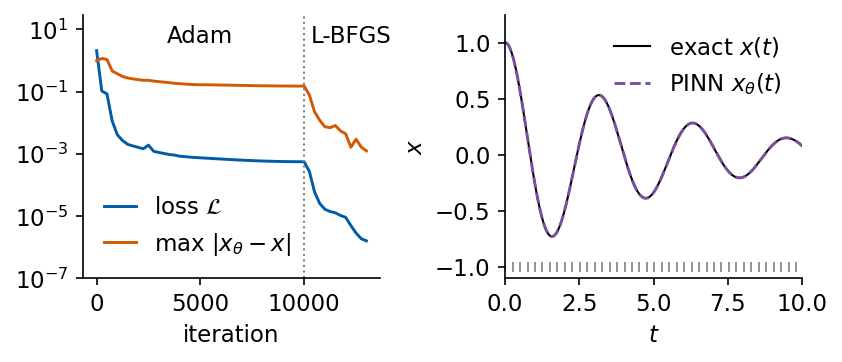

In [11]:
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.3), layout="constrained")
    ax = axs[0]
    ax.semilogy(hist_pinn["it"], hist_pinn["loss"], color=UJBlue, label=r"loss $\mathcal{L}$")
    ax.semilogy(hist_pinn["it"], hist_pinn["mon"], color=DSOrange, label=r"max $|x_\theta-x|$")
    ax.axvline(N_ADAM, color="0.5", ls=":", lw=1.0)
    ax.text(N_ADAM * 0.5, 6, "Adam", ha="center", va="center", fontsize=11)
    ax.text(N_ADAM + 300, 6, "L-BFGS", ha="left", va="center", fontsize=11)
    ax.set_xlabel("iteration"); ax.set_ylim(1e-7, 30); ax.legend(loc="lower left", fontsize=11, handlelength=1.4)
    ax = axs[1]
    ax.plot(T_DENSE, x_dense, color=COL["exact"], lw=1.0, label="exact $x(t)$")
    ax.plot(T_DENSE, x_pinn, "--", color=COL["PINN"], label=r"PINN $x_\theta(t)$")
    ax.plot(np.asarray(T_COL)[::5], np.full(N_R, -1.0)[::5], "|", color="0.5", ms=5, mew=0.8)   # every fifth collocation point
    ax.set_xlabel("$t$"); ax.set_ylabel("$x$"); ax.set_xlim(0, T_END); ax.set_ylim(-1.1, 1.25)
    ax.legend(loc="upper right", fontsize=11, handlelength=1.6)
    save(fig, "fig_lab041_pinn_training"); plt.show()

<hr/>
## 3. Accuracy and cost

A PINN solves the same initial-value problem that a classical integrator solves, so the two can be compared directly. The classical solvers integrate the first-order system for the state $\mathbf y=(x,\dot x)$,
$$\dot{\mathbf y}=\mathbf f(\mathbf y)=\Big(\dot x,\ -\frac{c\dot x+kx}{m}\Big). \tag{15}$$
We use our RK4 with a constant step $h$ and two solvers of diffrax [P. Kidger, *On Neural Differential Equations*, PhD thesis, University of Oxford (2021), [arXiv:2202.02435](https://arxiv.org/abs/2202.02435)]. The first is RK4 itself, defined through its Butcher tableau as a diffrax solver, which must reproduce our integrator to round-off. The second is Tsitouras' 5(4) Runge–Kutta pair (Tsit5) [Ch. Tsitouras, Comput. Math. Appl. **62**, 770 (2011), [doi:10.1016/j.camwa.2011.06.002](https://doi.org/10.1016/j.camwa.2011.06.002)] with adaptive step size. Each step of Tsit5 estimates its local error from the difference of a fifth- and a fourth-order solution, and a proportional–integral–derivative (PID) controller of diffrax shrinks or enlarges the step so that this estimate stays below the relative and absolute tolerances.

In [12]:
f_osc = lambda y: jnp.array([y[1], -(C_TRUE * y[1] + K * y[0]) / M])     # state y = (x, xdot)

class RK4(diffrax.AbstractERK):
    """Classical fourth-order Runge-Kutta method as a diffrax solver (Butcher tableau of RK4)."""
    tableau = diffrax.ButcherTableau(c=np.array([0.5, 0.5, 1.0]), b_sol=np.array([1/6, 1/3, 1/3, 1/6]),
                                     b_error=np.zeros(4),
                                     a_lower=(np.array([0.5]), np.array([0.0, 0.5]), np.array([0.0, 0.0, 1.0])))
    interpolation_cls = diffrax.ThirdOrderHermitePolynomialInterpolation.from_k

N_EVAL = [0]                      # counter of right-hand-side evaluations inside diffrax
def _bump(n):
    N_EVAL[0] += int(n); return np.int32(0)
def rhs_counted(t, y, args):
    io_callback(_bump, jax.ShapeDtypeStruct((), jnp.int32), 1, ordered=False)
    return f_osc(y)
rhs = lambda t, y, args: f_osc(y)

def dfx_solve(solver, ctrl, dt0, ts, counted=False):
    sol = diffrax.diffeqsolve(diffrax.ODETerm(rhs_counted if counted else rhs), solver, 0.0, T_END, dt0,
                              jnp.array([X0, V0]), saveat=diffrax.SaveAt(ts=ts), stepsize_controller=ctrl, max_steps=10**6)
    return sol.ys

def timed(fn, repeat=20):
    # median wall time of a compiled function, after one call for compilation
    jax.block_until_ready(fn()); ts_ = []
    for _ in range(repeat):
        t0 = time.perf_counter(); jax.block_until_ready(fn()); ts_.append(time.perf_counter() - t0)
    return float(np.median(ts_))

# own RK4 and diffrax RK4 with the same step h = 0.01
h = 0.01; n = int(round(T_END / h))
y_own = np.asarray(rk4_solve(f_osc, [X0, V0], h, n))
y_dfx = np.asarray(dfx_solve(RK4(), diffrax.ConstantStepSize(), h, jnp.arange(n + 1) * h))
print(f"h = {h}: max |own RK4 - diffrax RK4| = {np.abs(y_own - y_dfx).max():.1e},"
      f" max |own RK4 - exact x| = {np.abs(y_own[:, 0] - x_exact(np.arange(n + 1) * h)).max():.1e}")
nums["rk4_vs_diffrax"] = float(np.abs(y_own - y_dfx).max())

h = 0.01: max |own RK4 - diffrax RK4| = 1.8e-15, max |own RK4 - exact x| = 4.9e-09


With $h=0.01$ our RK4 and the diffrax RK4 agree to $1.8\times10^{-15}$, and both deviate from the analytical solution by $4.9\times10^{-9}$.

The cost of a classical integration is measured by the number of evaluations of the right-hand side $\mathbf f$ and by the wall time. RK4 evaluates $\mathbf f$ four times per step. For Tsit5 we count the evaluations with a callback inside the vector field, since the number of accepted and rejected steps is chosen by the controller. The accuracy is the largest deviation of $x$ from the analytical solution on $[0,10]$. For the PINN the corresponding numbers are the training time and the number of residual evaluations during training, one per collocation point and iteration, each of which costs a forward pass of the network and two derivatives. L-BFGS may evaluate the loss more than once per iteration in its line search, so this count is a lower bound. The classical-solver wall times are medians over repeated calls of compiled functions. Wall times depend on the hardware and concurrent system load; the numerical values below describe this recorded run.

In [13]:
rows = []
for h in (0.4, 0.2, 0.1, 0.05, 0.02, 0.01):
    n = int(round(T_END / h))
    fn = jax.jit(lambda: rk4_solve(f_osc, jnp.array([X0, V0]), h, n))
    y = np.asarray(fn())
    rows.append(dict(method="RK4", setting=h, nfe=4 * n, err=float(np.abs(y[:, 0] - x_exact(np.arange(n + 1) * h)).max()),
                     time=timed(fn)))
for tol in (1e-3, 1e-5, 1e-7, 1e-9, 1e-11):
    ctrl = diffrax.PIDController(rtol=tol, atol=tol)
    fn = jax.jit(lambda: dfx_solve(diffrax.Tsit5(), ctrl, 0.1, T_DENSE))
    y = np.asarray(fn())
    N_EVAL[0] = 0; jax.block_until_ready(dfx_solve(diffrax.Tsit5(), ctrl, 0.1, T_DENSE, counted=True))
    rows.append(dict(method="Tsit5", setting=tol, nfe=N_EVAL[0], err=float(np.abs(y[:, 0] - x_dense).max()), time=timed(fn)))

# PINN: one residual evaluation = network and its two time derivatives at one collocation point
t_eval_pinn = timed(jax.jit(lambda: jax.vmap(lambda t: net(p_pinn, t))(T_DENSE)))
rows.append(dict(method="PINN", setting="training", nfe=(N_ADAM + N_LBFGS) * N_R, err=float(err_pinn.max()),
                 time=hist_pinn["time"]))
print(f"{'method':7s} {'setting':>9s} {'evaluations':>12s} {'max error':>10s} {'time [s]':>10s}")
for r in rows:
    print(f"{r['method']:7s} {str(r['setting']):>9s} {r['nfe']:12d} {r['err']:10.1e} {r['time']:10.2e}")
print(f"evaluating the trained PINN on {len(T_DENSE)} times takes {t_eval_pinn:.1e} s")
nums["cost"] = rows; nums["pinn_eval_time"] = t_eval_pinn

method    setting  evaluations  max error   time [s]
RK4           0.4          100    1.3e-02   1.49e-05
RK4           0.2          200    8.0e-04   1.59e-05
RK4           0.1          400    5.0e-05   1.73e-05
RK4          0.05          800    3.1e-06   2.15e-05
RK4          0.02         2000    7.9e-08   3.32e-05
RK4          0.01         4000    4.9e-09   4.97e-05
Tsit5       0.001           97    4.4e-03   1.35e-04
Tsit5       1e-05          229    2.1e-05   1.76e-04
Tsit5       1e-07          596    1.1e-07   4.80e-04
Tsit5       1e-09         1406    8.9e-10   6.42e-04
Tsit5       1e-11         3459    8.0e-12   1.31e-03
PINN     training      2600000    1.2e-03   2.59e+01
evaluating the trained PINN on 2001 times takes 8.4e-04 s


The left panel plots the maximal error against the number of evaluations, the right panel against the wall time. Each RK4 point belongs to one step size, $h=0.4$ down to $0.01$, and each Tsit5 point to one tolerance, $10^{-3}$ down to $10^{-11}$. The PINN is a single point.

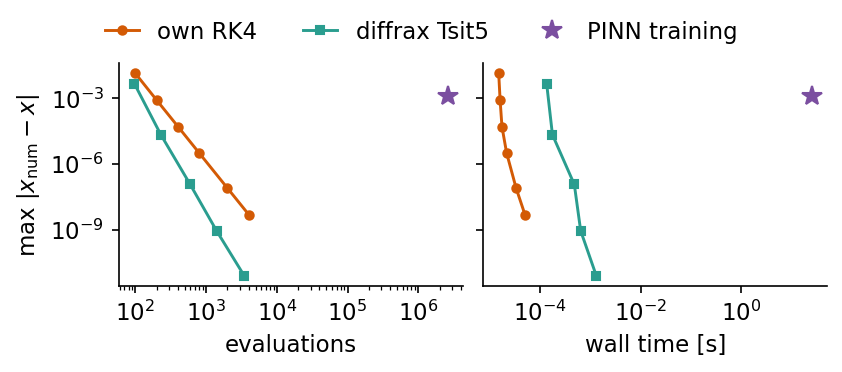

In [14]:
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.4), layout="constrained", sharey=True)
    for meth, mk in (("RK4", "o-"), ("Tsit5", "s-"), ("PINN", "*")):
        rr = [r for r in rows if r["method"] == meth]
        lab = {"RK4": "own RK4", "Tsit5": "diffrax Tsit5", "PINN": "PINN training"}[meth]
        axs[0].loglog([r["nfe"] for r in rr], [r["err"] for r in rr], mk, color=COL[meth], ms=(10 if meth == "PINN" else 4), label=lab)
        axs[1].loglog([r["time"] for r in rr], [r["err"] for r in rr], mk, color=COL[meth], ms=(10 if meth == "PINN" else 4))
    axs[0].set_xlabel("evaluations"); axs[0].set_ylabel(r"max $|x_{\rm num}-x|$")
    axs[1].set_xlabel("wall time [s]")
    fig.legend(*axs[0].get_legend_handles_labels(), loc="outside upper center", ncol=3, handlelength=1.5)
    save(fig, "fig_lab041_cost_accuracy"); plt.show()

The RK4 error falls by a factor of about 16 whenever $h$ is halved, from $8.0\times10^{-4}$ at $h=0.2$ to $5.0\times10^{-5}$ at $h=0.1$ and $3.1\times10^{-6}$ at $h=0.05$, the convergence of a fourth-order method. Tsit5 reaches $8.0\times10^{-12}$ with 3459 evaluations. The trained PINN deviates from the solution by $1.2\times10^{-3}$, after $2.6\times10^{6}$ residual evaluations and about 26 s of training in this recorded run. RK4 with $h=0.2$ is already more accurate, $8.0\times10^{-4}$, with 200 evaluations. The printed timing table compares its runtime with training and evaluating the PINN. These measurements depend on the machine and exclude compilation. For the initial-value problem of a low-dimensional ODE the PINN is a slow and inaccurate solver. Its construction becomes useful when the equation is combined with data, as the following experiments show.

### Sparse data with and without the residual

The residual term is what distinguishes a PINN from an ordinary fit. To isolate its effect we give the network 12 noise-free values of the analytical solution at equally spaced times in the window $0\le t\le4$, about the first 1.3 periods, and train the same architecture with the same optimiser twice. The first loss contains only the data term, $\frac1{N_d}\sum_j[x_\theta(t_j)-x_j]^2$. The second adds the mean squared residual at the 200 collocation points on the whole interval $[0,10]$. Neither loss contains an explicit initial-condition penalty. The position measurement at $t=0$ constrains the initial position only; positions at later times, together with the law in the second fit, constrain the motion and its initial velocity.

In [15]:
T_DATA_END, N_DATA = 4.0, 12
t_data = jnp.linspace(0.0, T_DATA_END, N_DATA)
x_data = jnp.asarray(x_exact(np.asarray(t_data)))       # noise-free samples of the exact solution

loss_data = make_osc_loss(net, d1, d2, T_COL, w_r=0.0, w_d=1.0, t_data=t_data, x_data=x_data, use_ic=False)
loss_phys = make_osc_loss(net, d1, d2, T_COL, w_r=1.0, w_d=1.0, t_data=t_data, x_data=x_data, use_ic=False)
p_data, h_data = train(loss_data, init_mlp(jax.random.key(0), SIZES), N_ADAM, N_LBFGS)
p_phys, h_phys = train(loss_phys, init_mlp(jax.random.key(0), SIZES), N_ADAM, N_LBFGS)
inside = np.asarray(T_DENSE) <= T_DATA_END
res_dp = {}
for name, p in (("data only", p_data), ("data + residual", p_phys)):
    e = np.abs(np.asarray(jax.vmap(lambda t: net(p, t))(T_DENSE)) - x_dense)
    res_dp[name] = dict(err_in=float(e[inside].max()), err_out=float(e[~inside].max()))
    print(f"{name:16s} max error for t <= {T_DATA_END:g}: {e[inside].max():.1e}, for t > {T_DATA_END:g}: {e[~inside].max():.1e}")
nums["data_vs_phys"] = res_dp

data only        max error for t <= 4: 2.6e-02, for t > 4: 1.2e+00
data + residual  max error for t <= 4: 3.6e-05, for t > 4: 3.0e-04


Inside the data window both networks follow the solution, with maximal errors of $2.6\times10^{-2}$ for the data-only fit and $3.6\times10^{-5}$ with the residual. Beyond the window the data-only network has no information. It continues smoothly and drifts away from the oscillation, with a maximal error of 1.2. The residual carries the solution through the remaining two periods with a maximal error of $3.0\times10^{-4}$, so the equation of motion turns 12 noise-free samples of the first 1.3 periods into the whole trajectory. The figure shows the analytical solution, the 12 data points (blue) in the shaded data window and the two trained networks. The continuation $4<t\le10$ is inside the collocation domain, where the equation was included in training. This experiment does not test extrapolation beyond the domain where the residual was penalised.

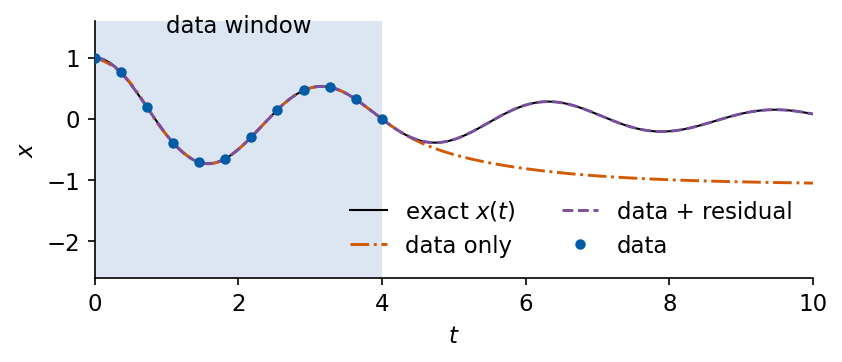

In [16]:
with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(5.5, 2.3), layout="constrained")
    ax.axvspan(0, T_DATA_END, color="#DCE6F2", lw=0, zorder=0)
    ax.text(T_DATA_END / 2, 1.33, "data window", ha="center", va="bottom")
    ax.plot(T_DENSE, x_dense, color=COL["exact"], lw=1.0, label="exact $x(t)$")
    ax.plot(T_DENSE, jax.vmap(lambda t: net(p_data, t))(T_DENSE), color=DSOrange, ls="-.", label="data only")
    ax.plot(T_DENSE, jax.vmap(lambda t: net(p_phys, t))(T_DENSE), "--", color=COL["PINN"], label="data + residual")
    ax.plot(t_data, x_data, "o", color=COL["data"], ms=4, label="data", zorder=5)
    ax.set_xlim(0, T_END); ax.set_ylim(-2.6, 1.6); ax.set_xlabel("$t$"); ax.set_ylabel("$x$")
    ax.legend(loc="lower right", ncol=2, fontsize=11, handlelength=1.6)
    save(fig, "fig_lab041_data_vs_physics"); plt.show()

<hr/>
## 4. Inverse problem

In an experiment the parameters of the equation are often unknown, and the measurements are noisy. The PINN treats an unknown parameter like a weight of the network. We assume that $m$ and $k$ are known and the damping coefficient $c$ is unknown, and we measure the position at 25 equally spaced times $t_j\in[0,10]$ with independent Gaussian noise of standard deviation $\sigma=0.02$,
$$y_j=x(t_j)+\sigma\varepsilon_j,\qquad \varepsilon_j\sim\mathcal N(0,1). \tag{16}$$
The initial state is treated as unknown as well, so the loss contains no initial-condition terms,
$$\mathcal L(\theta,c)=\frac1{N_{\rm obs}}\sum_{j=1}^{N_{\rm obs}}\big[x_\theta(t_j)-y_j\big]^2+\frac1{N_r}\sum_{i=1}^{N_r}r_{\theta,c}(t_i)^2, \tag{17}$$
where the residual $r_{\theta,c}$ uses the trainable $c$. Both terms are in units of a squared position, so equal weights penalise a violation of the equation of motion like a deviation from the data of the same size. We write $c=e^{s}$ and train $s$, which keeps $c$ positive, and start from $c=1.0$, two and a half times the true value $0.4$.

The classical reference is a least-squares fit of the analytical solution $x(t;c,x_0,v_0)$ to the same data with `scipy.optimize.least_squares`. Its standard error of $c$ follows from the Jacobian $J$ of the normalised residuals $(x(t_j)-y_j)/\sigma$ as the square root of the diagonal element of $(J^\top J)^{-1}$. We repeat both estimates for five independent noise realisations.

The observations must contain information about damping. A motion that remained at $x=0$ would satisfy the equation for every $c$ and could not identify it. Optimising the residual alone therefore cannot replace informative data for this inverse problem.


In [17]:
N_OBS, SIGMA_NOISE, C_INIT = 25, 0.02, 1.0
t_obs = jnp.linspace(0.0, T_END, N_OBS)

def inverse_loss(t_obs, y_obs):
    # parameters = (network parameters, log c); the residual uses the trainable damping c = exp(log c)
    def loss(q):
        params, logc = q
        c = jnp.exp(logc)
        r = jax.vmap(lambda t: (M * d2(params, t) + c * d1(params, t) + K * net(params, t)) / K)(T_COL)
        fit = jnp.mean((jax.vmap(lambda t: net(params, t))(t_obs) - y_obs)**2)
        return fit + jnp.mean(r**2)          # both terms in units of x squared, equal weights
    return loss

inv = []
for seed in range(5):
    rng = np.random.default_rng(seed)
    y_obs = jnp.asarray(x_exact(np.asarray(t_obs)) + SIGMA_NOISE * rng.normal(size=N_OBS))
    q0 = (init_mlp(jax.random.key(seed), SIZES), jnp.log(C_INIT))
    q, h_inv = train(inverse_loss(t_obs, y_obs), q0, N_ADAM, N_LBFGS, monitor=lambda q: float(jnp.exp(q[1])))
    # classical reference: least-squares fit of (c, x0, v0) in the closed-form solution
    ls = least_squares(lambda z: (x_exact(np.asarray(t_obs), z[0], z[1], z[2]) - np.asarray(y_obs)) / SIGMA_NOISE,
                       x0=[C_INIT, 0.5, 0.5])
    cov = np.linalg.inv(ls.jac.T @ ls.jac)
    inv.append(dict(seed=seed, c_pinn=float(jnp.exp(q[1])), c_ls=float(ls.x[0]), c_ls_err=float(np.sqrt(cov[0, 0])),
                    hist=h_inv, q=q, y_obs=y_obs))
    print(f"noise seed {seed}: c_PINN = {inv[-1]['c_pinn']:.4f}, c_least-squares = {ls.x[0]:.4f} +- {np.sqrt(cov[0, 0]):.4f},"
          f" {h_inv['time']:.0f} s")
cp = np.array([r["c_pinn"] for r in inv]); cl = np.array([r["c_ls"] for r in inv])
print(f"true c = {C_TRUE}; PINN mean {cp.mean():.4f}, std {cp.std(ddof=1):.4f};"
      f" least squares mean {cl.mean():.4f}, std {cl.std(ddof=1):.4f}; max |c_PINN - c_LS| = {np.abs(cp - cl).max():.4f}")
nums["inverse"] = dict(c_true=C_TRUE, c_init=C_INIT, n_obs=N_OBS, sigma=SIGMA_NOISE, c_pinn=cp.tolist(), c_ls=cl.tolist(),
                       c_ls_err=[r["c_ls_err"] for r in inv], pinn_mean=cp.mean(), pinn_std=cp.std(ddof=1),
                       ls_mean=cl.mean(), ls_std=cl.std(ddof=1), max_diff=float(np.abs(cp - cl).max()))

noise seed 0: c_PINN = 0.4000, c_least-squares = 0.4035 +- 0.0099, 28 s
noise seed 1: c_PINN = 0.3977, c_least-squares = 0.3971 +- 0.0098, 27 s
noise seed 2: c_PINN = 0.4006, c_least-squares = 0.3975 +- 0.0098, 27 s
noise seed 3: c_PINN = 0.4103, c_least-squares = 0.4048 +- 0.0099, 27 s
noise seed 4: c_PINN = 0.3958, c_least-squares = 0.3962 +- 0.0099, 27 s
true c = 0.4; PINN mean 0.4009, std 0.0056; least squares mean 0.3998, std 0.0040; max |c_PINN - c_LS| = 0.0054


The left panel shows the estimate of $c$ during the training for the five noise realisations, with the true value dotted and the switch from Adam to L-BFGS marked by the vertical line. The right panel shows the noisy data of the first realisation, the trained network and the analytical solution.

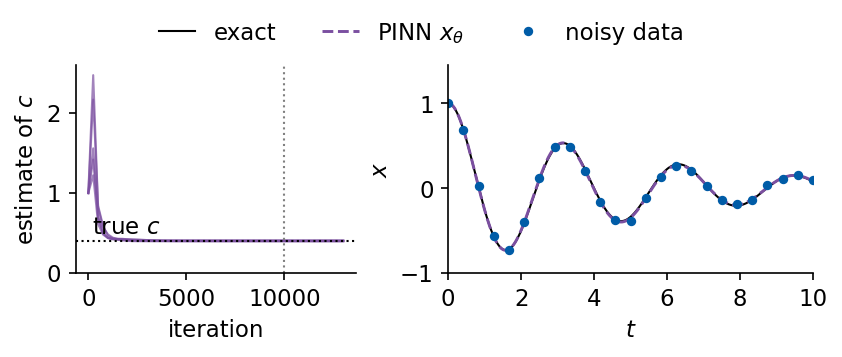

In [18]:
r0 = inv[0]
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.3), layout="constrained", gridspec_kw={"width_ratios": [1, 1.3]})
    ax = axs[0]
    for r in inv:
        ax.plot(r["hist"]["it"], r["hist"]["mon"], color=COL["PINN"], lw=1.0, alpha=0.7)
    ax.axhline(C_TRUE, color="k", ls=":", lw=1.0); ax.text(200, C_TRUE + 0.03, "true $c$", va="bottom")
    ax.axvline(N_ADAM, color="0.5", ls=":", lw=1.0)
    c_top = max(float(np.max(r["hist"]["mon"])) for r in inv)
    ax.set_xlabel("iteration"); ax.set_ylabel("estimate of $c$"); ax.set_ylim(0, 1.05 * c_top)
    ax = axs[1]
    ax.plot(T_DENSE, x_dense, color=COL["exact"], lw=1.0, label="exact")
    ax.plot(T_DENSE, jax.vmap(lambda t: net(r0["q"][0], t))(T_DENSE), "--", color=COL["PINN"], label=r"PINN $x_\theta$")
    ax.plot(t_obs, r0["y_obs"], "o", color=COL["data"], ms=3.5, label="noisy data")
    ax.set_xlabel("$t$"); ax.set_ylabel("$x$"); ax.set_xlim(0, T_END); ax.set_ylim(-1.0, 1.45)
    fig.legend(*ax.get_legend_handles_labels(), loc="outside upper center", ncol=3, fontsize=11, handlelength=1.6)
    save(fig, "fig_lab041_inverse"); plt.show()

In the first few hundred Adam steps all five estimates rise above the starting value $c=1.0$, then they fall to the neighbourhood of the true value within the Adam stage and stay there under L-BFGS. For the first noise realisation the PINN gives $c=0.4000$ and the least-squares fit $0.4035\pm0.0099$. Over the five realisations the PINN estimates have the mean 0.4009 and the standard deviation 0.0056, the least-squares estimates 0.3998 and 0.0040. On the same data the two estimates differ by at most 0.0054, less than the statistical error 0.0099 of the least-squares fit. The spread of the PINN estimates, 0.0056, is somewhat larger than that of the fit, 0.0040, and five realisations are too few to decide whether this difference is significant. The PINN thus recovers the damping within the noise of the data, with a precision at most comparable to that of the classical fit. The least-squares fit uses the analytical solution, while the PINN needs only the equation of motion, which makes the same procedure applicable to equations without a solution formula.

<hr/>
## 5. Heat equation

### Diffusion in a rod

A thin rod conducts heat along its axis, and its two ends are held at the same fixed temperature. We measure the position $x$ along the rod in units of its length and the temperature $u(x,t)$ relative to that of the ends. Fourier's law states that the heat current is proportional to $-\partial_xu$, and the conservation of energy then gives the heat equation
$$\partial_tu=D\,\partial_x^2u,\qquad 0<x<1,\quad 0<t\le t_{\max}, \tag{18}$$
with the boundary and initial conditions
$$u(0,t)=u(1,t)=0,\qquad u(x,0)=u_0(x). \tag{19}$$
The thermal diffusivity $D$ sets the time scale of the conduction. The same equation describes every diffusion process, with $u$ a concentration and $D$ the diffusion coefficient. Integrating the equation over the rod gives
$$\frac{d}{dt}\int_0^1u\,dx=D\big[\partial_xu(1,t)-\partial_xu(0,t)\big], \tag{20}$$
so the heat content of the rod changes only through the heat currents at its ends.

The product ansatz $u=X(x)\,T(t)$ separates the equation into $X''/X=\dot T/(DT)=-\lambda$. The boundary conditions admit only $X_n(x)=\sin n\pi x$ with $\lambda_n=n^2\pi^2$, $n=1,2,\dots$, and every such mode decays exponentially in time,
$$\begin{aligned}
u(x,t)&=\sum_{n=1}^\infty b_n\,e^{-t/\tau_n}\sin n\pi x,\\
\tau_n&=\frac{1}{Dn^2\pi^2},\qquad b_n=2\int_0^1u_0(x)\sin n\pi x\,dx .
\end{aligned} \tag{21}$$
A mode with $n$ half-wavelengths along the rod decays $n^2$ times faster than the lowest mode, so fine structure in the temperature profile disappears first and the profile approaches the shape $\sin\pi x$ while its amplitude decays.

We take $D=0.1$, $t_{\max}=1$ and the initial profile $u_0(x)=\sin\pi x+\tfrac12\sin3\pi x$, for which $b_1=1$, $b_3=\tfrac12$ and all other coefficients vanish. We evaluate $\tau_1$ and $\tau_3$ and check with central finite differences that the series solves the heat equation.

In [19]:
D_TRUE, T_MAX = 0.1, 1.0              # thermal diffusivity and end of the time window
B_HEAT = {1: 1.0, 3: 0.5}             # Fourier coefficients b_n of the initial profile

def u0_heat(x):
    return sum(b * jnp.sin(n * jnp.pi * x) for n, b in B_HEAT.items())

def u_heat(x, t, D=D_TRUE):
    # separation of variables: every sine mode decays with the rate D n^2 pi^2
    return sum(b * np.exp(-D * n**2 * np.pi**2 * t) * np.sin(n * np.pi * x) for n, b in B_HEAT.items())

tau = {n: 1 / (D_TRUE * n**2 * np.pi**2) for n in B_HEAT}
# residual of the series solution with central finite differences on a grid of test points
xx, tq = np.meshgrid(np.linspace(0.05, 0.95, 19), np.linspace(0.05, 0.95, 19)); e = 1e-4
res_fd = ((u_heat(xx, tq + e) - u_heat(xx, tq - e)) / (2 * e)
          - D_TRUE * (u_heat(xx + e, tq) - 2 * u_heat(xx, tq) + u_heat(xx - e, tq)) / e**2)
print(f"tau_1 = {tau[1]:.4f}, tau_3 = {tau[3]:.4f}; amplitudes at t = {T_MAX:g}:"
      f" mode 1 {np.exp(-T_MAX / tau[1]):.3f}, mode 3 {0.5 * np.exp(-T_MAX / tau[3]):.1e}")
print(f"max |finite-difference residual of the series solution| = {np.abs(res_fd).max():.1e}")
nums["heat"] = dict(D=D_TRUE, t_max=T_MAX, tau1=tau[1], tau3=tau[3], amp1_end=float(np.exp(-T_MAX / tau[1])),
                    amp3_end=float(0.5 * np.exp(-T_MAX / tau[3])))

tau_1 = 1.0132, tau_3 = 0.1126; amplitudes at t = 1: mode 1 0.373, mode 3 6.9e-05
max |finite-difference residual of the series solution| = 5.8e-07


The mode $n=1$ decays with the time $\tau_1=1.013$ and the mode $n=3$ with $\tau_3=0.113$, nine times faster. At $t=1$ the amplitude of the first mode has dropped to 0.373 and that of the third to $6.9\times10^{-5}$. The finite-difference residual of the series is $5.8\times10^{-7}$, the size of the truncation error of the differences. The left panel shows the temperature $u(x,t)$ as a colour map in the plane of the position $x$ and the time $t$, and the middle panel the profiles $u(x,t)$ at five times. The two maxima of the initial profile, which come from the mode $n=3$, have almost merged into a flat top at $t=0.2$, and afterwards the profile keeps the shape $\sin\pi x$ while it decays. The right panel shows the amplitudes $b_ne^{-t/\tau_n}$ of the two modes on a logarithmic axis, straight lines with the slopes $-1/\tau_n$.

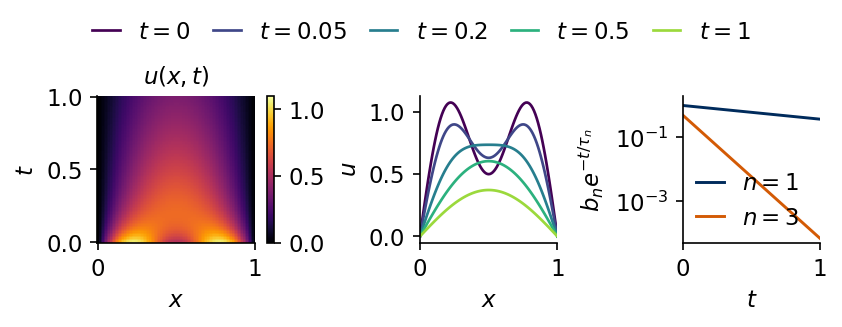

In [20]:
XH, TH = np.meshgrid(np.linspace(0, 1, 101), np.linspace(0, T_MAX, 101))     # evaluation grid, rows = times
UH = u_heat(XH, TH)
T_PROF = (0.0, 0.05, 0.2, 0.5, 1.0)
prof_cols = plt.cm.viridis(np.linspace(0.0, 0.85, len(T_PROF)))
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 3, figsize=(5.5, 2.1), layout="constrained", gridspec_kw={"width_ratios": [1.15, 1, 1]})
    im = axs[0].pcolormesh(XH, TH, UH, cmap="inferno", vmin=0, vmax=1.1, shading="auto", rasterized=True)
    axs[0].set_xlabel("$x$"); axs[0].set_ylabel("$t$"); axs[0].set_title("$u(x,t)$")
    fig.colorbar(im, ax=axs[0], ticks=[0, 0.5, 1], fraction=0.08, pad=0.03)
    for tk, cc in zip(T_PROF, prof_cols):
        axs[1].plot(XH[0], u_heat(XH[0], tk), color=cc, lw=1.3, label=f"$t={tk:g}$")
    axs[1].set_xlabel("$x$"); axs[1].set_ylabel("$u$"); axs[1].set_xlim(0, 1)
    tt_h = np.linspace(0, T_MAX, 201)
    for n, b in B_HEAT.items():
        axs[2].semilogy(tt_h, b * np.exp(-tt_h / tau[n]), color=(UJNavy if n == 1 else DSOrange), label=f"$n={n}$")
    axs[2].set_xlabel("$t$"); axs[2].set_ylabel(r"$b_n e^{-t/\tau_n}$"); axs[2].set_xlim(0, T_MAX); axs[2].set_ylim(5e-5, 2)
    axs[2].legend(loc="lower left", fontsize=11, handlelength=1.2, borderaxespad=0.2)
    fig.legend(*axs[1].get_legend_handles_labels(), loc="outside upper center", ncol=len(T_PROF), fontsize=11,
               handlelength=1.2, columnspacing=1.0)
    save(fig, "fig_lab041_heat_exact"); plt.show()

### Crank–Nicolson solver

The classical reference is a finite-difference solution on the grid $x_i=i\,\Delta x$, $\Delta x=1/N_x$, and $t^n=n\,\Delta t$, $\Delta t=t_{\max}/N_t$. The numbers $U_i^n$ approximate $u(x_i,t^n)$, and the second derivative is replaced by the second difference $\delta^2U_i=U_{i+1}-2U_i+U_{i-1}$. The Crank–Nicolson scheme averages this difference over the old and the new time level [J. Crank and P. Nicolson, Proc. Cambridge Philos. Soc. **43**, 50 (1947), [doi:10.1017/S0305004100023197](https://doi.org/10.1017/S0305004100023197)],
$$\frac{U_i^{n+1}-U_i^n}{\Delta t}=\frac{D}{2\Delta x^2}\big(\delta^2U_i^{n+1}+\delta^2U_i^n\big),\qquad U_0^n=U_{N_x}^n=0 . \tag{22}$$
Every time step solves a tridiagonal linear system for the $N_x-1$ interior values, which costs a number of operations proportional to $N_x$. The error decreases as $\Delta x^2+\Delta t^2$, and the scheme is stable for every $\Delta t$. The explicit scheme with the forward difference in time needs no linear solve but is stable only for $D\Delta t/\Delta x^2\le\tfrac12$. We solve on grids with $N_x=N_t=10,20,\dots,160$, measure the error as the largest deviation $\max_{i,n}|U_i^n-u(x_i,t^n)|$ from the series solution over all grid nodes, and record the median wall time of the compiled solver.

In [21]:
def cn_solve(D, nx, nt):
    # Crank-Nicolson for u_t = D u_xx with u(0,t) = u(1,t) = 0; returns U[n, i] at t^n = n dt, x_i = i dx
    dx, dt = 1.0 / nx, T_MAX / nt
    a = 0.5 * D * dt / dx**2
    m = nx - 1                                             # number of interior nodes
    dl = jnp.full(m, -a).at[0].set(0.0); du = jnp.full(m, -a).at[-1].set(0.0); dd = jnp.full(m, 1 + 2 * a)
    def step(u, _):
        rhs = (1 - 2 * a) * u + a * (jnp.pad(u[1:], (0, 1)) + jnp.pad(u[:-1], (1, 0)))   # (1 + D dt/2 delta^2) U^n
        u = jax.lax.linalg.tridiagonal_solve(dl, dd, du, rhs[:, None])[:, 0]           # (1 - D dt/2 delta^2) U^{n+1} = rhs
        return u, u
    u_in = u0_heat(jnp.linspace(0.0, 1.0, nx + 1)[1:-1])
    _, us = jax.lax.scan(step, u_in, None, length=nt)
    return jnp.pad(jnp.concatenate([u_in[None], us]), ((0, 0), (1, 1)))     # add the boundary nodes

rows_heat = []
for nx in (10, 20, 40, 80, 160):
    fn = jax.jit(lambda: cn_solve(D_TRUE, nx, nx))
    U = np.asarray(fn())
    xg_, tg_ = np.meshgrid(np.linspace(0, 1, nx + 1), np.linspace(0, T_MAX, nx + 1))
    rows_heat.append(dict(nx=nx, err=float(np.abs(U - u_heat(xg_, tg_)).max()), time=timed(fn)))
    print(f"N_x = N_t = {nx:3d}: max |U - u| = {rows_heat[-1]['err']:.2e}, wall time {rows_heat[-1]['time']:.1e} s")
nums["heat_fd"] = rows_heat

N_x = N_t =  10: max |U - u| = 2.73e-03, wall time 3.1e-05 s
N_x = N_t =  20: max |U - u| = 6.81e-04, wall time 5.0e-05 s
N_x = N_t =  40: max |U - u| = 1.70e-04, wall time 1.0e-04 s
N_x = N_t =  80: max |U - u| = 4.25e-05, wall time 3.6e-04 s
N_x = N_t = 160: max |U - u| = 1.06e-05, wall time 9.2e-04 s


The error falls by a factor of four whenever the grid spacing and the time step are halved, from $2.7\times10^{-3}$ at $N_x=10$ to $1.1\times10^{-5}$ at $N_x=160$, the second-order convergence of the scheme. The printed timing table reports wall times below a millisecond on all five grids. These timings depend on the machine.

### PINN of the heat equation

The network $u_\theta(x,t)$ now has two inputs. Both are rescaled to $[-1,1]$, and the hidden layers are those of the oscillator, three layers of 32 tanh units. The residual of the heat equation is
$$r_\theta(x,t)=\partial_tu_\theta(x,t)-D\,\partial_x^2u_\theta(x,t), \tag{23}$$
where `jax.grad` with respect to $t$ gives the time derivative and `jax.hessian` with respect to $x$ the second space derivative. The loss contains three terms,
$$\begin{aligned}
\mathcal L(\theta)={}&\frac1{N_r}\sum_{i=1}^{N_r}r_\theta(x_i,t_i)^2+\frac1{N_0}\sum_{k=1}^{N_0}\big[u_\theta(x_k,0)-u_0(x_k)\big]^2\\
&+\frac1{N_b}\sum_{l=1}^{N_b}\big[u_\theta(0,t_l)^2+u_\theta(1,t_l)^2\big].
\end{aligned} \tag{24}$$
The first term is the mean squared residual at $N_r=41\times41=1681$ collocation points $(x_i,t_i)$ on a regular grid of the domain $[0,1]\times[0,t_{\max}]$. The second term enforces the initial profile at $N_0=101$ equally spaced positions $x_k$, and the third term the boundary conditions at $N_b=51$ equally spaced times $t_l$ at both ends. All weights equal one. Every loss evaluation costs about eight times as many network passes as for the oscillator, and we shorten the training to 5000 Adam steps with the cosine schedule and 2000 L-BFGS iterations. The error is the largest deviation $\max|u_\theta-u|$ from the series solution on a grid of $101\times101$ points.

In [22]:
SIZES_H = [2] + [WIDTH] * DEPTH + [1]

def heat_net(params, x, t):
    # network u_theta(x, t); both inputs rescaled to [-1, 1]
    h = jnp.array([2 * x - 1, 2 * t / T_MAX - 1])
    for W, b in params[:-1]:
        h = jnp.tanh(W @ h + b)
    W, b = params[-1]
    return (W @ h + b)[0]
heat_ut = jax.grad(heat_net, argnums=2)              # du_theta/dt
heat_uxx = jax.hessian(heat_net, argnums=1)          # d^2u_theta/dx^2

N_XC = 41
XC, TC = [jnp.asarray(a.ravel()) for a in np.meshgrid(np.linspace(0, 1, N_XC), np.linspace(0, T_MAX, N_XC))]
X_IC = jnp.linspace(0.0, 1.0, 101); U_IC = u0_heat(X_IC)
T_BC = jnp.linspace(0.0, T_MAX, 51)

def make_heat_loss(split, x_obs=None, t_obs=None, y_obs=None):
    # split(q) returns (network parameters, D); the data term is added when observations are given
    def loss(q):
        params, D = split(q)
        r = jax.vmap(lambda x, t: heat_ut(params, x, t) - D * heat_uxx(params, x, t))(XC, TC)
        L = jnp.mean(r**2)
        L += jnp.mean((jax.vmap(lambda x: heat_net(params, x, 0.0))(X_IC) - U_IC)**2)
        L += jnp.mean(jax.vmap(lambda t: heat_net(params, 0.0, t)**2 + heat_net(params, 1.0, t)**2)(T_BC))
        if y_obs is not None:
            L += jnp.mean((jax.vmap(lambda x, t: heat_net(params, x, t))(x_obs, t_obs) - y_obs)**2)
        return L
    return loss

heat_field = jax.jit(lambda p: jax.vmap(lambda x, t: heat_net(p, x, t))(jnp.asarray(XH.ravel()), jnp.asarray(TH.ravel())).reshape(XH.shape))
heat_err = lambda p: float(np.abs(np.asarray(heat_field(p)) - UH).max())

N_ADAM_H, N_LBFGS_H = 5000, 2000
p_heat0 = init_mlp(jax.random.key(0), SIZES_H)
p_heat, hist_heat = train(make_heat_loss(lambda q: (q, D_TRUE)), p_heat0, N_ADAM_H, N_LBFGS_H, monitor=heat_err)
U_pinn = np.asarray(heat_field(p_heat))
i_sw = np.searchsorted(hist_heat["it"], N_ADAM_H)
fd_better = [r for r in rows_heat if r["err"] < hist_heat["mon"][-1]]
print(f"network {SIZES_H}, {n_params(p_heat0)} parameters; {N_ADAM_H} Adam + {N_LBFGS_H} L-BFGS iterations in {hist_heat['time']:.1f} s")
print(f"final loss {hist_heat['final_loss']:.1e}; max |u_PINN - u|: after Adam {hist_heat['mon'][i_sw - 1]:.1e}, final {heat_err(p_heat):.1e}")
print(f"coarsest Crank-Nicolson grid more accurate than the PINN: N_x = {fd_better[0]['nx']},"
      f" error {fd_better[0]['err']:.1e}, {fd_better[0]['time']:.1e} s")
nums["heat_pinn"] = dict(n_params=n_params(p_heat0), time=hist_heat["time"], loss=hist_heat["final_loss"],
                         err_adam=float(hist_heat["mon"][i_sw - 1]), err=heat_err(p_heat), n_col=N_XC**2,
                         fd_nx=fd_better[0]["nx"], fd_err=fd_better[0]["err"], fd_time=fd_better[0]["time"])

network [2, 32, 32, 32, 1], 2241 parameters; 5000 Adam + 2000 L-BFGS iterations in 53.7 s
final loss 3.0e-06; max |u_PINN - u|: after Adam 6.8e-03, final 1.2e-03
coarsest Crank-Nicolson grid more accurate than the PINN: N_x = 20, error 6.8e-04, 5.0e-05 s


The network has 2241 parameters, and the 7000 iterations take about 54 s in the recorded execution. At the end of the Adam stage the maximal error is $6.8\times10^{-3}$, and L-BFGS lowers it to $1.2\times10^{-3}$ at the final loss $3.0\times10^{-6}$. The left panel compares the PINN (dashed) with the series solution (black) at three times. The middle panel shows the absolute error $|u_\theta-u|$ over the domain, multiplied by $10^3$. The right panel shows the maximal error $\max|u_{\rm num}-u|$ against the wall time, for the Crank–Nicolson solutions on the five grids and for the training of the PINN (star).

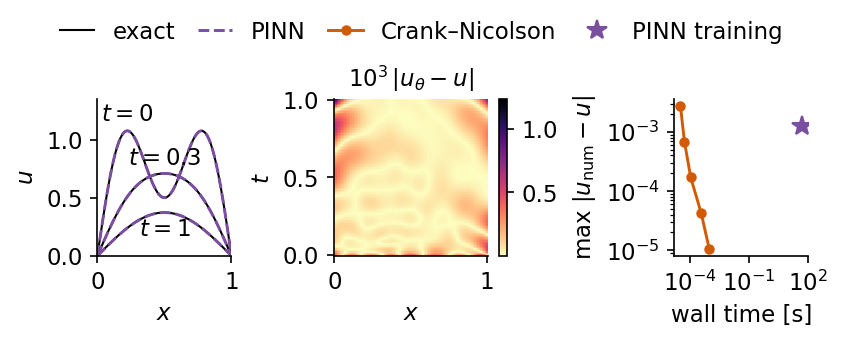

In [23]:
def label_profiles(ax, times, place):
    # time labels next to the profiles; place[t] = (x, y, va)
    for tk in times:
        x_, y_, va = place[tk]
        ax.text(x_, y_, f"$t={tk:g}$", ha="center", va=va, fontsize=11)

with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 3, figsize=(5.5, 2.2), layout="constrained", gridspec_kw={"width_ratios": [1, 1.15, 1]})
    ax = axs[0]
    for j, tk in enumerate((0.0, 0.3, 1.0)):
        k = int(round(tk / T_MAX * 100))
        ax.plot(XH[0], UH[k], color="k", lw=1.0, label=("exact" if j == 0 else None))
        ax.plot(XH[0], U_pinn[k], "--", color=COL["PINN"], lw=1.4, label=("PINN" if j == 0 else None))
    label_profiles(ax, (0.0, 0.3, 1.0), {0.0: (0.22, 1.12, "bottom"), 0.3: (0.5, 0.74, "bottom"), 1.0: (0.5, 0.33, "top")})
    ax.set_xlabel("$x$"); ax.set_ylabel("$u$"); ax.set_xlim(0, 1); ax.set_ylim(0, 1.35)
    ax = axs[1]
    im = ax.pcolormesh(XH, TH, 1e3 * np.abs(U_pinn - UH), cmap="magma_r", shading="auto", rasterized=True)
    ax.set_xlabel("$x$"); ax.set_ylabel("$t$")
    fig.colorbar(im, ax=ax, fraction=0.08, pad=0.03)
    ax.set_title(r"$10^3\,|u_\theta-u|$")
    ax = axs[2]
    ax.loglog([r["time"] for r in rows_heat], [r["err"] for r in rows_heat], "o-", color=COL["RK4"], ms=4, label="Crank–Nicolson")
    ax.loglog([hist_heat["time"]], [hist_heat["mon"][-1]], "*", color=COL["PINN"], ms=10, label="PINN training")
    ax.set_xlabel("wall time [s]"); ax.set_ylabel(r"max $|u_{\rm num}-u|$")
    ax.set_xticks([1e-4, 1e-1, 1e2])
    fig.legend(*[a + b for a, b in zip(axs[0].get_legend_handles_labels(), axs[2].get_legend_handles_labels())],
               loc="outside upper center", ncol=4, fontsize=11, handlelength=1.5, columnspacing=1.0)
    save(fig, "fig_lab041_heat_pinn"); plt.show()

The error of the PINN is largest close to the corners $x=0$ and $x=1$ at $t=1$ and along the initial line $t=0$, where the loss balances the initial profile, the boundary conditions and the residual against each other. The Crank–Nicolson solution on the grid $N_x=N_t=20$ is already more accurate, with the error $6.8\times10^{-4}$, and its measured runtime is printed above alongside the training time. For the forward problem of the heat equation with known $D$ and known initial and boundary conditions the finite-difference solver is the better tool, as the RK4 integration was for the oscillator. A grid in one space dimension is cheap. The mesh-free formulation of a PINN can matter for many space dimensions or irregular domains, which we do not test here.

### Thermal diffusivity from four thermometers

In the inverse problem the diffusivity $D$ is unknown, and four thermometers at the fixed positions $x_s=0.1,\,0.3,\,0.55,\,0.8$ record the temperature at the 20 times $t_j=0.05\,j$, $j=1,\dots,20$. The readings carry independent Gaussian noise of standard deviation $\sigma=0.01$,
$$y_{sj}=u(x_s,t_j)+\sigma\varepsilon_{sj},\qquad \varepsilon_{sj}\sim\mathcal N(0,1). \tag{25}$$
The initial profile and the temperature of the ends are known. The loss of the forward problem receives the data term
$$\mathcal L_{\rm data}(\theta)=\frac1{N_{\rm obs}}\sum_{s,j}\big[u_\theta(x_s,t_j)-y_{sj}\big]^2,\qquad N_{\rm obs}=80, \tag{26}$$
and the residual uses the trainable diffusivity $D=e^{s}$, written through its logarithm $s$ so that it stays positive. Training starts from $D=0.3$, three times the true value, with the same budget as the forward problem. The trained network is at the same time an estimate of the whole temperature field $u(x,t)$ that is consistent with the heat equation and with the sparse readings, a simple example of data assimilation, the estimation of the state of a system from a model combined with incomplete measurements.

The classical reference fits $D$ through the Crank–Nicolson solver. On the grid $N_x=100$, $N_t=200$ the thermometer positions and reading times are grid nodes, and `scipy.optimize.least_squares` minimises the sum of the squared normalised deviations $[U(x_s,t_j;D)-y_{sj}]/\sigma$ over $D$. Its standard error follows from the Jacobian as for the oscillator. We repeat both estimates for five noise realisations.

In [24]:
X_SENS = np.array([0.1, 0.3, 0.55, 0.8]); T_READ = 0.05 * np.arange(1, 21); SIGMA_HEAT, D_INIT = 0.01, 0.3
XO, TO = [jnp.asarray(a.ravel()) for a in np.meshgrid(X_SENS, T_READ)]    # readings ordered by time, then position
NX_LS, NT_LS = 100, 200
IX = np.round(X_SENS * NX_LS).astype(int); IT = np.round(T_READ / T_MAX * NT_LS).astype(int)
cn_at_sensors = jax.jit(lambda D: cn_solve(D, NX_LS, NT_LS)[IT][:, IX].ravel())
jax.block_until_ready(cn_at_sensors(D_INIT))                                 # compile once

inv_heat = []
for seed in range(5):
    rng = np.random.default_rng(100 + seed)
    y_h = jnp.asarray(u_heat(np.asarray(XO), np.asarray(TO)) + SIGMA_HEAT * rng.normal(size=XO.shape))
    q0 = (init_mlp(jax.random.key(seed), SIZES_H), jnp.log(D_INIT))
    q, h_h = train(make_heat_loss(lambda q: (q[0], jnp.exp(q[1])), XO, TO, y_h), q0, N_ADAM_H, N_LBFGS_H,
                   monitor=lambda q: float(jnp.exp(q[1])))
    t0 = time.perf_counter()
    ls = least_squares(lambda z: (np.asarray(cn_at_sensors(z[0])) - np.asarray(y_h)) / SIGMA_HEAT, x0=[D_INIT])
    t_ls = time.perf_counter() - t0
    inv_heat.append(dict(D_pinn=float(jnp.exp(q[1])), D_ls=float(ls.x[0]), D_ls_err=float(np.sqrt(np.linalg.inv(ls.jac.T @ ls.jac)[0, 0])),
                         field_err=heat_err(q[0]), time=h_h["time"], t_ls=t_ls, nfev=int(ls.nfev), hist=h_h, q=q, y=y_h))
    r = inv_heat[-1]
    print(f"noise seed {seed}: D_PINN = {r['D_pinn']:.5f}, D_least-squares = {r['D_ls']:.5f} +- {r['D_ls_err']:.5f},"
          f" max |u_PINN - u| = {r['field_err']:.1e}, PINN {r['time']:.0f} s, least squares {t_ls:.2f} s ({r['nfev']} solver calls)")
dp = np.array([r["D_pinn"] for r in inv_heat]); dl_ = np.array([r["D_ls"] for r in inv_heat])
print(f"true D = {D_TRUE}; PINN mean {dp.mean():.5f}, std {dp.std(ddof=1):.5f}; least squares mean {dl_.mean():.5f},"
      f" std {dl_.std(ddof=1):.5f}; max |D_PINN - D_LS| = {np.abs(dp - dl_).max():.5f}")
nums["heat_inverse"] = dict(D_true=D_TRUE, D_init=D_INIT, n_sensors=len(X_SENS), n_times=len(T_READ), sigma=SIGMA_HEAT,
                            D_pinn=dp.tolist(), D_ls=dl_.tolist(), D_ls_err=[r["D_ls_err"] for r in inv_heat],
                            pinn_mean=dp.mean(), pinn_std=dp.std(ddof=1), ls_mean=dl_.mean(), ls_std=dl_.std(ddof=1),
                            max_diff=float(np.abs(dp - dl_).max()), field_err=[r["field_err"] for r in inv_heat],
                            time_pinn=float(np.mean([r["time"] for r in inv_heat])),
                            time_ls=float(np.mean([r["t_ls"] for r in inv_heat])))

noise seed 0: D_PINN = 0.10005, D_least-squares = 0.09987 +- 0.00051, max |u_PINN - u| = 1.6e-03, PINN 62 s, least squares 0.23 s (8 solver calls)
noise seed 1: D_PINN = 0.09971, D_least-squares = 0.09975 +- 0.00051, max |u_PINN - u| = 3.8e-03, PINN 63 s, least squares 0.02 s (8 solver calls)
noise seed 2: D_PINN = 0.10071, D_least-squares = 0.10054 +- 0.00051, max |u_PINN - u| = 2.5e-03, PINN 58 s, least squares 0.02 s (8 solver calls)
noise seed 3: D_PINN = 0.09951, D_least-squares = 0.09967 +- 0.00051, max |u_PINN - u| = 1.9e-03, PINN 61 s, least squares 0.02 s (8 solver calls)
noise seed 4: D_PINN = 0.09921, D_least-squares = 0.09910 +- 0.00051, max |u_PINN - u| = 3.4e-03, PINN 65 s, least squares 0.02 s (8 solver calls)
true D = 0.1; PINN mean 0.09984, std 0.00058; least squares mean 0.09978, std 0.00052; max |D_PINN - D_LS| = 0.00018


The left panel shows the error $|u_\theta-u|$ of the reconstructed field of the first noise realisation, multiplied by $10^3$, with the 80 thermometer readings as white dots. The middle panel shows the estimate of $D$ during the training for the five realisations, with the true value dotted and the switch from Adam to L-BFGS marked by the vertical line. The right panel compares the reconstructed profiles (dashed) with the series solution (black) at three reading times, together with the readings at these times (blue dots).

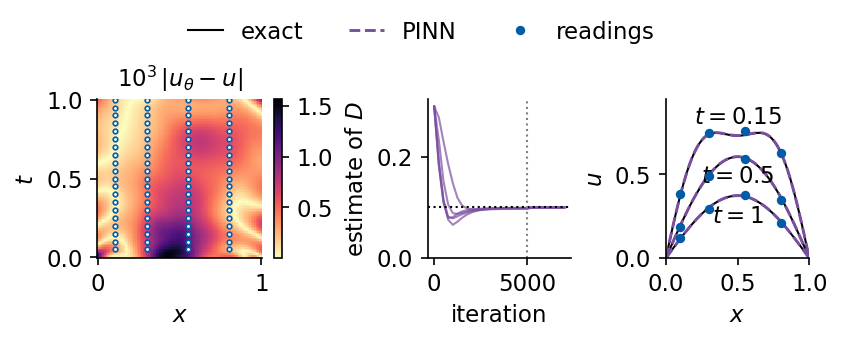

In [25]:
r0h = inv_heat[0]
U_rec = np.asarray(heat_field(r0h["q"][0]))
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 3, figsize=(5.5, 2.2), layout="constrained", gridspec_kw={"width_ratios": [1.15, 1, 1]})
    ax = axs[0]
    im = ax.pcolormesh(XH, TH, 1e3 * np.abs(U_rec - UH), cmap="magma_r", shading="auto", rasterized=True)
    ax.plot(np.asarray(XO), np.asarray(TO), "o", ms=2.2, mfc="white", mec=COL["data"], mew=0.8)
    fig.colorbar(im, ax=ax, fraction=0.08, pad=0.03)
    ax.set_xlabel("$x$"); ax.set_ylabel("$t$"); ax.set_title(r"$10^3\,|u_\theta-u|$")
    ax = axs[1]
    for r in inv_heat:
        ax.plot(r["hist"]["it"], r["hist"]["mon"], color=COL["PINN"], lw=1.0, alpha=0.7)
    ax.axhline(D_TRUE, color="k", ls=":", lw=1.0); ax.axvline(N_ADAM_H, color="0.5", ls=":", lw=1.0)
    ax.set_xlabel("iteration"); ax.set_ylabel("estimate of $D$"); ax.set_ylim(0, 1.05 * max(float(np.max(r["hist"]["mon"])) for r in inv_heat))
    ax.set_xticks([0, 5000])
    ax = axs[2]
    T_SHOW = (0.15, 0.5, 1.0)
    for j, tk in enumerate(T_SHOW):
        k = int(round(tk / T_MAX * 100)); jr = int(round(tk / 0.05)) - 1
        ax.plot(XH[0], UH[k], color="k", lw=1.0, label=("exact" if j == 0 else None))
        ax.plot(XH[0], U_rec[k], "--", color=COL["PINN"], lw=1.4, label=("PINN" if j == 0 else None))
        ax.plot(X_SENS, np.asarray(r0h["y"]).reshape(len(T_READ), len(X_SENS))[jr], "o", color=COL["data"], ms=3.5, zorder=5,
                label=("readings" if j == 0 else None))
    label_profiles(ax, T_SHOW, {0.15: (0.5, 0.77, "bottom"), 0.5: (0.5, 0.56, "top"), 1.0: (0.5, 0.32, "top")})
    ax.set_xlabel("$x$"); ax.set_ylabel("$u$"); ax.set_xlim(0, 1); ax.set_ylim(0, 0.95)
    fig.legend(*ax.get_legend_handles_labels(), loc="outside upper center", ncol=3, fontsize=11, handlelength=1.5)
    save(fig, "fig_lab041_heat_inverse"); plt.show()

In all five realisations the estimate of $D$ falls from its starting value 0.3 below the true value early in the Adam stage, then approaches the true value and stays there under L-BFGS. For the first realisation the PINN gives $D=0.10005$ and the least-squares fit $0.09987\pm0.00051$. Over the five realisations the PINN estimates have the mean 0.09984 and the standard deviation 0.00058, the least-squares estimates 0.09978 and 0.00052. On the same data the two estimates differ by at most 0.00018, less than half of the statistical error of the fit, so for this problem the PINN and the classical fit give the same diffusivity within the noise. The reconstructed field deviates from the series solution by at most $1.6\times10^{-3}$ for the first realisation and by at most $3.8\times10^{-3}$ over all five, compared with $1.2\times10^{-3}$ for the forward PINN with known $D$.

In this recorded run, the five fits take 58–65 seconds per PINN training, while the least-squares fit uses 8 solver calls and takes 0.02–0.23 seconds on the same machine. The Crank–Nicolson solution with the fitted $D$ also gives the whole field, so in this setting with a known initial profile the PINN offers no advantage in accuracy or cost. The advantage of the PINN lies in its structure, since the same loss accepts an unknown initial profile, readings at arbitrary positions and times, or an equation for which no solver has been written, by adding or removing terms, while the classical route needs a new solver or a new fitting procedure for each such change. We do not test these extensions.

<hr/>
## 6. Pendulum over several periods

For the pendulum the network $\theta_{\rm PINN}(t)$ has the residual $r(t)=\ddot\theta_{\rm PINN}(t)+\omega_p^2\sin\theta_{\rm PINN}(t)$, and the loss contains its mean square and the initial conditions $\theta_{\rm PINN}(0)=\theta_0$, $\dot\theta_{\rm PINN}(0)=0$ with unit weights. We keep the network, the optimiser and the training budget of the oscillator, place 100 collocation points per period and train on windows of one, two and four periods $T_p$, each with three random initialisations (seeds). A second experiment trains in time order, one network per period, each started from the end state $(\theta_{\rm PINN},\dot\theta_{\rm PINN})$ of the previous one, a procedure called time marching. The error is measured against the RK4 reference with step $10^{-3}$.

In [26]:
def pend_pinn(t_a, t_b, y0, n_col, seed=0):
    # PINN theta_PINN(t) for theta'' + omega_p^2 sin(theta) = 0 on [t_a, t_b] with theta(t_a), theta'(t_a) = y0
    net_p, d1_p, d2_p = make_net(t_a, t_b)
    t_col = jnp.linspace(t_a, t_b, n_col)
    def loss(p):
        r = jax.vmap(lambda t: d2_p(p, t) + OMEGA_P2 * jnp.sin(net_p(p, t)))(t_col)
        return jnp.mean(r**2) + (net_p(p, t_a) - y0[0])**2 + (d1_p(p, t_a) - y0[1])**2
    p, h = train(loss, init_mlp(jax.random.key(seed), SIZES), N_ADAM, N_LBFGS)
    th = lambda t: np.asarray(jax.vmap(lambda s: net_p(p, s))(jnp.asarray(t)))
    om = lambda t: np.asarray(jax.vmap(lambda s: d1_p(p, s))(jnp.asarray(t)))
    return th, om, h

N_COL_PER = 100                       # collocation points per period
t_ref = t_pend[::10]; th_ref = Y_pend[::10, 0]          # RK4 reference on a grid of spacing 0.01
pend_runs = {}
for n_per in (1, 2, 4):
    for seed in (0, 1, 2):
        th, om, h = pend_pinn(0.0, n_per * T_PEND, (TH0, 0.0), N_COL_PER * n_per, seed)
        m = t_ref <= n_per * T_PEND + 1e-9
        e = np.abs(th(t_ref[m]) - th_ref[m])
        bad = np.nonzero(e > 0.1)[0]
        pend_runs[(n_per, seed)] = dict(err=float(e.max()), loss=h["final_loss"], time=h["time"], th=th,
                                        t_fail=float(t_ref[m][bad[0]]) if len(bad) else None)
        print(f"window {n_per} period(s), seed {seed}: final loss {h['final_loss']:.1e}, max |theta_PINN - theta_RK4| ="
              f" {e.max():.1e}, first time with error > 0.1: {pend_runs[(n_per, seed)]['t_fail']}, {h['time']:.0f} s")
nums["pend_windows"] = {f"{k[0]} {k[1]}": dict(err=v["err"], loss=v["loss"], t_fail=v["t_fail"]) for k, v in pend_runs.items()}

window 1 period(s), seed 0: final loss 6.4e-08, max |theta_PINN - theta_RK4| = 6.9e-05, first time with error > 0.1: None, 17 s
window 1 period(s), seed 1: final loss 6.2e-08, max |theta_PINN - theta_RK4| = 6.7e-05, first time with error > 0.1: None, 18 s
window 1 period(s), seed 2: final loss 6.7e-09, max |theta_PINN - theta_RK4| = 3.7e-05, first time with error > 0.1: None, 17 s
window 2 period(s), seed 0: final loss 3.1e-03, max |theta_PINN - theta_RK4| = 5.1e+00, first time with error > 0.1: 1.95, 23 s
window 2 period(s), seed 1: final loss 3.1e-03, max |theta_PINN - theta_RK4| = 5.1e+00, first time with error > 0.1: 1.95, 22 s
window 2 period(s), seed 2: final loss 3.1e-03, max |theta_PINN - theta_RK4| = 5.1e+00, first time with error > 0.1: 1.95, 22 s
window 4 period(s), seed 0: final loss 1.3e-05, max |theta_PINN - theta_RK4| = 6.5e-02, first time with error > 0.1: None, 36 s
window 4 period(s), seed 1: final loss 1.2e-05, max |theta_PINN - theta_RK4| = 5.2e-02, first time with 

In [27]:
N_MARCH = 4
y0 = (TH0, 0.0); march = []; t0 = time.time()
for j in range(N_MARCH):
    t_a, t_b = j * T_PEND, (j + 1) * T_PEND
    th, om, h = pend_pinn(t_a, t_b, y0, N_COL_PER, seed=0)
    march.append(dict(t_a=t_a, t_b=t_b, th=th, loss=h["final_loss"]))
    y0 = (float(th([t_b])[0]), float(om([t_b])[0]))        # end state = initial condition of the next window
t_march = time.time() - t0
th_m = np.concatenate([w["th"](t_ref[(t_ref >= w["t_a"]) & (t_ref < w["t_b"])]) for w in march])
m = t_ref < N_MARCH * T_PEND
err_m = np.abs(th_m - th_ref[m])
err_end = [float(err_m[(t_ref[m] >= w["t_a"]) & (t_ref[m] < w["t_b"])].max()) for w in march]
fn_rk4 = jax.jit(lambda: rk4_solve(f_pend, jnp.array([TH0, 0.0]), 0.01, int(N_MARCH * T_PEND / 0.01)))
t_rk4 = timed(fn_rk4, 5)
print(f"time marching over {N_MARCH} windows of one period: {t_march:.0f} s of training")
print("max error per window: " + ", ".join(f"{e:.1e}" for e in err_end))
print(f"RK4 with h = 0.01 over the same {N_MARCH} periods: {t_rk4:.1e} s")
nums["march"] = dict(n=N_MARCH, time=t_march, err=err_end, rk4_time=t_rk4)

time marching over 4 windows of one period: 68 s of training
max error per window: 6.9e-05, 3.5e-04, 7.7e-04, 1.4e-03
RK4 with h = 0.01 over the same 4 periods: 3.0e-04 s


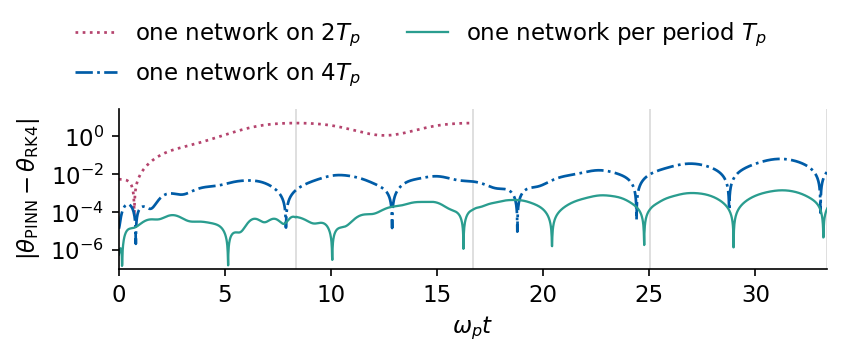

In [28]:
n_show = max(k[0] for k in pend_runs)
with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(5.5, 2.3), layout="constrained")
    for n_per, ls, cc in ((2, ":", "#B5446E"), (n_show, "-.", UJBlue)):
        mm = t_ref <= n_per * T_PEND + 1e-9
        ax.semilogy(t_ref[mm], np.abs(pend_runs[(n_per, 0)]["th"](t_ref[mm]) - th_ref[mm]) + 1e-12, ls, color=cc, lw=1.3,
                    label=rf"one network on ${n_per}T_p$")
    ax.semilogy(t_ref[m], err_m + 1e-12, color=COL["Tsit5"], lw=1.1, label=r"one network per period $T_p$")
    for j in range(1, n_show + 1):
        ax.axvline(j * T_PEND, color="0.85", lw=0.8, zorder=0)
    ax.set_ylabel(r"$|\theta_{\rm PINN}-\theta_{\rm RK4}|$"); ax.set_xlabel(r"$\omega_p t$")
    ax.set_ylim(1e-7, 30); ax.set_yticks([1e-6, 1e-4, 1e-2, 1e0]); ax.set_xlim(0, n_show * T_PEND)
    fig.legend(*ax.get_legend_handles_labels(), loc="outside upper center", ncol=2, fontsize=11, handlelength=1.8)
    save(fig, "fig_lab041_pendulum_long"); plt.show()

On one period all three seeds reach maximal errors between $3.7\times10^{-5}$ and $6.9\times10^{-5}$. On two periods all three seeds converge to the same function with the loss $3.1\times10^{-3}$, which leaves the solution at $t=1.95$ and settles at the upright position $\theta=-\pi$. The equilibrium portion has a small residual, but the preceding transient need not obey the equation accurately. The loss averages the squared residuals, so the number of collocation points does not itself increase their weight relative to the initial conditions. Since the initial-position penalty is nonnegative and part of the total loss, its error is at most $\sqrt{0.0031}\simeq0.056$. The failed fit therefore cannot be the constant curve $-\pi$ that ignores its initial position. A small average loss can coexist with a large trajectory error. On four periods seeds 0 and 1 reach errors of $6.5\times10^{-2}$ and $5.2\times10^{-2}$, and seed 2 fails in the same way with an error of 5.1. Failures of this kind are documented for PINNs and attributed to the optimisation of the residual loss [Krishnapriyan *et al.*, NeurIPS 2021, [arXiv:2109.01050](https://arxiv.org/abs/2109.01050)]. Training one network per period avoids the large failure in the tested run, and the error grows from $6.9\times10^{-5}$ in the first window to $1.4\times10^{-3}$ in the fourth, since every window starts from the slightly wrong end state of the previous one. In this recorded run the four trainings take 68 s, and RK4 with $h=0.01$ integrates the same four periods in $3.0\times10^{-4}$ s. Wang, Sankaran and Perdikaris reach a similar ordering in time within a single network by weighting the residual at later times by the size of the residual at earlier times [[arXiv:2203.07404](https://arxiv.org/abs/2203.07404)]. The figure shows the deviation $|\theta_{\rm PINN}-\theta_{\rm RK4}|$ on a logarithmic axis for the networks of seed 0 trained on two and on four periods and for the training with one network per period, whose first window is the one-period network. The thin vertical lines mark multiples of $T_p$.

<hr/>
## Accuracy, inverse problems and optimisation limits

A physics-informed neural network represents the solution of a differential equation by a multilayer perceptron and trains it on the mean squared residual of the equation at collocation points, with the derivatives from automatic differentiation, plus penalty terms for the initial and boundary conditions and for data. On the damped oscillator the network with 2209 parameters reaches a maximal error of $1.2\times10^{-3}$ after 10000 Adam and 3000 L-BFGS iterations. A fourth-order Runge–Kutta integration with $h=0.2$ is more accurate and more than a million times faster, and the adaptive Tsit5 solver of diffrax reaches $8\times10^{-12}$ with a few thousand evaluations, so for a forward initial-value problem of a low-dimensional ODE the PINN does not compete with a classical solver.

The residual becomes useful in combination with data. Twelve noise-free samples of the first 1.3 periods suffice to reconstruct the oscillation over the whole window with an error of $3.0\times10^{-4}$, where a fit of the same network to the data alone drifts away by 1.2 outside the data window. With noisy observations and an unknown damping the same loss estimates $c$ together with the trajectory, $0.4009\pm0.0056$ over five noise realisations for the true value 0.4, against $0.3998\pm0.0040$ for a least-squares fit of the analytical solution.

The heat equation $\partial_tu=D\partial_x^2u$ in a rod repeats both findings for a partial differential equation. With known $D$ the PINN reaches $1.2\times10^{-3}$, while a Crank–Nicolson solver on a grid of $20\times20$ points is more accurate in a time about a million times shorter. With $D$ unknown and four thermometers read at 20 times with noise $\sigma=0.01$, the PINN estimates $D=0.09984\pm0.00058$ for the true value 0.1, the same within the noise as a least-squares fit through the Crank–Nicolson solver, $0.09978\pm0.00052$, and returns the whole temperature field with an error of a few times $10^{-3}$. The classical fit is again much faster.

The pendulum shows the main weakness of the method. On one period the PINN agrees with RK4 to below $10^{-4}$, while on longer windows the fitted curve can depart from the reference and approach the upright equilibrium despite a small average loss. Training one network per period avoids this failure in the tested run at a cost many orders of magnitude above that of RK4. These conclusions refer to the networks, budgets and problems studied here.

## References

- I. E. Lagaris, A. Likas, D. I. Fotiadis, *Artificial neural networks for solving ordinary and partial differential equations*, IEEE Trans. Neural Netw. **9**, 987 (1998), [doi:10.1109/72.712178](https://doi.org/10.1109/72.712178)
- M. Raissi, P. Perdikaris, G. E. Karniadakis, *Physics-informed neural networks: a deep learning framework for solving forward and inverse problems involving nonlinear partial differential equations*, J. Comput. Phys. **378**, 686 (2019), [doi:10.1016/j.jcp.2018.10.045](https://doi.org/10.1016/j.jcp.2018.10.045)
- J. Crank, P. Nicolson, *A practical method for numerical evaluation of solutions of partial differential equations of the heat-conduction type*, Proc. Cambridge Philos. Soc. **43**, 50 (1947), [doi:10.1017/S0305004100023197](https://doi.org/10.1017/S0305004100023197)
- S. H. Strogatz, *Nonlinear Dynamics and Chaos*, 2nd ed., CRC Press (2018), [doi:10.1201/9780429492563](https://doi.org/10.1201/9780429492563)
- E. Hairer, S. P. Nørsett, G. Wanner, *Solving Ordinary Differential Equations I. Nonstiff Problems*, 2nd ed., Springer (1993), [doi:10.1007/978-3-540-78862-1](https://doi.org/10.1007/978-3-540-78862-1)
- Ch. Tsitouras, *Runge–Kutta pairs of order 5(4) satisfying only the first column simplifying assumption*, Comput. Math. Appl. **62**, 770 (2011), [doi:10.1016/j.camwa.2011.06.002](https://doi.org/10.1016/j.camwa.2011.06.002)
- P. Kidger, *On Neural Differential Equations*, PhD thesis, University of Oxford (2021), [arXiv:2202.02435](https://arxiv.org/abs/2202.02435)
- D. P. Kingma, J. Ba, *Adam: a method for stochastic optimization*, [arXiv:1412.6980](https://arxiv.org/abs/1412.6980)
- D. C. Liu, J. Nocedal, *On the limited memory BFGS method for large scale optimization*, Math. Program. **45**, 503 (1989), [doi:10.1007/BF01589116](https://doi.org/10.1007/BF01589116)
- S. Wang, Y. Teng, P. Perdikaris, *Understanding and mitigating gradient pathologies in physics-informed neural networks*, [arXiv:2001.04536](https://arxiv.org/abs/2001.04536)
- A. S. Krishnapriyan, A. Gholami, S. Zhe, R. M. Kirby, M. W. Mahoney, *Characterizing possible failure modes in physics-informed neural networks*, NeurIPS 2021, [arXiv:2109.01050](https://arxiv.org/abs/2109.01050)
- S. Wang, S. Sankaran, P. Perdikaris, *Respecting causality is all you need for training physics-informed neural networks*, [arXiv:2203.07404](https://arxiv.org/abs/2203.07404)

The numbers quoted in the text are collected in a JSON file and as LaTeX macros.

In [29]:
nums["runtime_s"] = round(time.time() - t_start, 1)
def to_py(o):
    if isinstance(o, dict): return {str(k): to_py(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [to_py(v) for v in o]
    if isinstance(o, (np.floating, np.integer)): return o.item()
    if isinstance(o, jnp.ndarray): return to_py(np.asarray(o).tolist())
    return o
with open(f"{OUT}/numbers_lab041.json", "w") as fh:
    json.dump(to_py(nums), fh, indent=1)

def sci(x, d=1):
    # LaTeX scientific notation a\times10^{b}
    m, e = f"{x:.{d}e}".split("e")
    return f"{m}\\times10^{{{int(e)}}}"
NUMTAG = {1: "One", 2: "Two", 4: "Four"}
macros = {}
o = nums["osc"]
macros["Zeta"] = f"{o['zeta']:.2f}"; macros["OmegaD"] = f"{o['omegad']:.3f}"; macros["PeriodOsc"] = f"{o['period']:.2f}"
macros["EnergyRatio"] = f"{o['E_ratio']:.3f}"
macros["PeriodPend"] = f"{nums['pend']['period']:.3f}"; macros["PeriodRatio"] = f"{nums['pend']['ratio_small']:.3f}"
macros["Params"] = str(nums["n_params"])
p_ = nums["pinn_osc"]
macros["TrainTime"] = f"{p_['time']:.0f}"; macros["ErrAdam"] = sci(p_["err_adam"]); macros["ErrPINN"] = sci(p_["err"])
macros["LossPINN"] = sci(p_["loss"])
for r in rows:
    if r["method"] == "RK4" and r["setting"] in (0.1, 0.01):
        tag = {0.1: "PointOne", 0.01: "PointZeroOne"}[r["setting"]]
        macros[f"ErrRKFour{tag}"] = sci(r["err"]); macros[f"TimeRKFour{tag}"] = sci(r["time"]); macros[f"NfeRKFour{tag}"] = str(r["nfe"])
macros["NfePINN"] = str((N_ADAM + N_LBFGS) * N_R)
for name, tag in (("data only", "DataOnly"), ("data + residual", "DataPhys")):
    macros[f"ErrIn{tag}"] = sci(nums["data_vs_phys"][name]["err_in"]); macros[f"ErrOut{tag}"] = sci(nums["data_vs_phys"][name]["err_out"])
iv = nums["inverse"]
macros["CPinnMean"] = f"{iv['pinn_mean']:.3f}"; macros["CPinnStd"] = f"{iv['pinn_std']:.3f}"
macros["CLsMean"] = f"{iv['ls_mean']:.3f}"; macros["CLsStd"] = f"{iv['ls_std']:.3f}"
macros["CPinnSeedZero"] = f"{iv['c_pinn'][0]:.3f}"; macros["CLsSeedZero"] = f"{iv['c_ls'][0]:.3f}"
for n_per in (1, 2, 4):
    errs = [pend_runs[(n_per, s)]["err"] for s in (0, 1, 2)]
    macros[f"PendErrMax{NUMTAG[n_per]}"] = sci(max(errs)); macros[f"PendErrMin{NUMTAG[n_per]}"] = sci(min(errs))
macros["MarchErrLast"] = sci(nums["march"]["err"][-1]); macros["MarchErrFirst"] = sci(nums["march"]["err"][0])
macros["MarchTime"] = f"{nums['march']['time']:.0f}"
hh, hf, hi = nums["heat"], nums["heat_pinn"], nums["heat_inverse"]
macros["HeatDTrue"] = f"{hh['D']:g}"; macros["HeatTMax"] = f"{hh['t_max']:g}"
macros["HeatTauOne"] = f"{hh['tau1']:.3f}"; macros["HeatTauThree"] = f"{hh['tau3']:.3f}"
macros["HeatParams"] = str(hf["n_params"]); macros["HeatNCol"] = str(hf["n_col"])
macros["HeatErrPINN"] = sci(hf["err"]); macros["HeatErrAdam"] = sci(hf["err_adam"]); macros["HeatLossPINN"] = sci(hf["loss"])
macros["HeatTimePINN"] = f"{hf['time']:.0f}"
macros["HeatFDNx"] = str(hf["fd_nx"]); macros["HeatErrFD"] = sci(hf["fd_err"]); macros["HeatTimeFD"] = sci(hf["fd_time"])
fd_fine = nums["heat_fd"][-1]
macros["HeatFDNxFine"] = str(fd_fine["nx"]); macros["HeatErrFDFine"] = sci(fd_fine["err"]); macros["HeatTimeFDFine"] = sci(fd_fine["time"])
macros["HeatNSensors"] = str(hi["n_sensors"]); macros["HeatNTimes"] = str(hi["n_times"]); macros["HeatSigma"] = f"{hi['sigma']:g}"
macros["HeatDInit"] = f"{hi['D_init']:g}"
macros["HeatDPinnMean"] = f"{hi['pinn_mean']:.4f}"; macros["HeatDPinnStd"] = f"{hi['pinn_std']:.4f}"
macros["HeatDLsMean"] = f"{hi['ls_mean']:.4f}"; macros["HeatDLsStd"] = f"{hi['ls_std']:.4f}"
macros["HeatDLsErr"] = f"{hi['D_ls_err'][0]:.4f}"
macros["HeatFieldErr"] = sci(hi["field_err"][0]); macros["HeatFieldErrMax"] = sci(max(hi["field_err"]))
macros["HeatTimeInv"] = f"{hi['time_pinn']:.0f}"; macros["HeatTimeLs"] = f"{hi['time_ls']:.2f}"
macros["Runtime"] = f"{nums['runtime_s'] / 60:.1f}"
bad = [k for k in macros if not k.isalpha()]
assert not bad, bad
with open(f"{OUT}/nb_numbers_lab041.tex", "w") as fh:
    for k, val in macros.items():
        fh.write(f"\\newcommand{{\\labfortyone{k}}}{{{val}}}\n")
print(f"{len(macros)} macros written; total runtime {nums['runtime_s'] / 60:.1f} min")

67 macros written; total runtime 16.0 min
